# Repairing the iteration-8 research record: the alias-manifold test (item 0e)

**Artifact `art_iYh9zVP7myjJ`, iteration 9, Step 0** of an AI Inventor run that asks how "creativity" shows up inside an LLM: which path-search algorithm a code model chooses to write, and whether a prompt can push it somewhere new.

`eval.py` repairs the iteration-8 research record on CPU only (no model runs, USD 0). In the full run it:
- recomputes every number that a correction quotes into a **298-value ledger** (147 MATCH, 151 NEW, 0 CORRECTED, 0 CARRIED); each value carries a source `<artifact_id>:<path>#<key>`;
- writes **49 verbatim edits** into the report, each tagged *(iteration-9 correction)*; the apply test passes and the whole-report residual-claim lint drops from **28 live hits to 0**;
- runs one new computation, **item 0e**, which this notebook reproduces end to end.

**The question behind 0e.** Iteration 8 reported that when the prompt banned the five most common algorithms (BFS, DFS, IDDFS, A\* and greedy best-first), the model's choice landed *opposite* them: on unit-weight Dijkstra, the algorithm farthest from the banned five on a geodesic manifold of Qwen3-32B residual states. That manifold has 300 "forced" prompts (10 algorithms × 10 templates × 3 aliases, block 31). The prompts name every algorithm by three aliases, though, and some aliases share words with banned names: "bidirectional **BFS**", "**A\*** run from both start and goal". So is *edge versus opposite* just a matter of shared words? Item 0e scores each of the 15 non-banned alias sets by its lexical overlap with the banned names. It computes each set's geodesic distance `g` to the banned five, then correlates the two:
- **across algorithms**, Spearman rho is −0.61 at k = 15 (exact p 0.0093 over all 360,360 arrangements) and −0.77 at k = 10;
- **within an algorithm**, with the algorithm held fixed, the statistic is only −0.12 (p 0.46);
- **the committed verdict is CONFOUNDED**: this manifold cannot tell names apart from mechanisms.

**What runs here.** Every input comes from `mini_demo_data.json`. The notebook loads it from GitHub and falls back to a local copy.

| `eval.py` stage | in this notebook |
|-|-|
| `setup`: hash the report and the 53 input files | not run (needs the 1.4 MB report and the six iteration-8 artifacts) |
| `0e`: gates E1–E3, alias-level `g`, exact nulls, stratified test, bootstrap, placebos, verdict, figure | **runs in full** on iteration 8's stored geodesics |
| optional BPE-token sensitivity (`src/tertiary_bpe.py`) | runs if the Qwen3-32B `tokenizer.json` (11 MB) can be downloaded |
| `ledger`, `edits`, apply test, lint, audits | not run (they read the six iteration-8 artifacts); the final summary shows their recorded results |
| `eval_out` | the 0e part (the `alias_overlap` dataset and the `alias_*` metrics) is rebuilt and compared with the record |

The cells contain the original code of `eval.py`, `src/alias_geometry.py`, `src/stage_0e.py` and `src/tertiary_bpe.py`. The only changes read inputs from the loaded data instead of from files, and each is marked `# original: ...`.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (eval.py and src/stage_0e.py log through it)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, tokenizers, huggingface_hub — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'tokenizers==0.22.2', 'huggingface_hub==1.4.0')

In [2]:
# ---- eval.py (import block as in the original) ----
from __future__ import annotations

import argparse
import csv
import datetime as dt
import hashlib
import json
import os
import resource
import sys
import time
from collections import Counter
from pathlib import Path
from typing import Any

from loguru import logger

# ---- src/alias_geometry.py ----
import ast
import itertools
import math
import re

import numpy as np
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components, shortest_path
from scipy.spatial import ConvexHull, cKDTree
from scipy.spatial.distance import cdist
from scipy.stats import rankdata

# ---- src/stage_0e.py (its other imports are already above) ----
import gc

# ---- src/tertiary_bpe.py ----
import glob

from tokenizers import Tokenizer

# ---- notebook additions: inline figures ----
import matplotlib.pyplot as plt
from IPython.display import Image, display

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-9/evaluation-8/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()

# What was loaded: one dataset (the 20 alias_overlap examples of full_eval_out.json) and the stored inputs that recompute it
geo_in = data["inputs"]["geo_C6_nf4"]
print(data["metadata"]["title"])
print(f"dataset '{data['dataset']}': {len(data['examples'])} examples (15 alias sets + 5 algorithm centroids)")
print(f"stored geodesics: k15 {len(geo_in['geo_k15'])} x {len(geo_in['geo_k15'][0])}, "
      f"k10 {len(geo_in['geo_k10'])} x {len(geo_in['geo_k10'][0])}, block L = {geo_in['L']}, "
      f"{len(geo_in['labels'])} labels")
print("prompt index rows:", len(data["inputs"]["forced_index_C6_nf4"]["kind"]),
      "| algorithms:", data["inputs"]["common_py"]["CANON_ORDER"])
for k, v in data["metadata"]["source_sha256"].items():
    print(f"  sha256 {k:<26} {v[:16]}…")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Repairing the iteration-8 research record: demo data for item 0e (the alias-named manifold)
dataset 'alias_overlap': 20 examples (15 alias sets + 5 algorithm centroids)
stored geodesics: k15 300 x 300, k10 300 x 300, block L = 31, 300 labels
prompt index rows: 317 | algorithms: ['bfs', 'dfs', 'bibfs', 'iddfs', 'astar', 'gbfs', 'dijkstra_unit', 'idastar', 'jps', 'biastar']
  sha256 geo_C6_nf4.npz             6fc240fffcfc16a6…
  sha256 forced_index_C6_nf4.json   5511df916fb5eb02…
  sha256 common.py                  dc3a7a26af140cbc…
  sha256 geometry_M1.json           12761d7d18bf83a8…
  sha256 full_eval_out.json         f5724b130054e46e…


## Configuration

Item 0e has four tunable sample sizes. Everything else is either an **exact** computation that cannot be shrunk without changing the answer, or fixed by the pre-commitment:
- the exact nulls enumerate all 360,360 arrangements of the primary overlap multiset, the 5! = 120 centroid permutations and the (3!)^5 = 7,776 within-algorithm relabelings;
- `SEED = 20261023` and the detectors are fixed in `predictions/commit_s0e.json`.

| parameter | what it controls | original |
|-|-|-|
| `N_BOOT` | template cluster-bootstrap resamples behind the 95% intervals | 2,000 |
| `N_PLACEBO` | draws for each of the placebos P1, P2 and P3 | 1,000 |
| `N_MC_SECONDARY` | Monte Carlo null draws for an overlap score with more than 2×10^6 arrangements (the content-word score has 5.4 M; the BPE score has 1.4×10^10) | 200,000 |
| `N_PLANTED` | seeds of the planted control C1 (seed 0 decides pass/fail; all seeds give its power) | 200 |

Smaller values only make the bootstrap intervals, the Monte Carlo p-values and the placebo rates noisier, and these then no longer match the record digit for digit. The exact statistics, the gates and the verdict do not depend on these sizes.

**The notebook uses the original values.** In a clean Colab-like environment the whole notebook runs in about 35 s, install cell included. Stage 0e itself takes about 10 s, and runtime barely changes between the smallest sizes (10 / 10 / 1,000 / 2) and the original ones. At the original sizes every recomputed metric matches the record, including the random-draw ones: numpy's seeded generator gives the same stream on Colab's numpy 2.0.2 as on the numpy 2.5.4 of the original run.

In [5]:
# Tunable sizes of item 0e (module constants of src/alias_geometry.py, plus the planted-control loop of src/stage_0e.py).
# These are the original values; with them the whole notebook runs in about half a minute on a CPU.
N_BOOT = 2000             # template cluster-bootstrap resamples          (original: 2000)
N_PLACEBO = 1000          # draws per placebo P1, P2, P3                   (original: 1000)
N_MC_SECONDARY = 200_000  # Monte Carlo null draws (> 2e6 arrangements)    (original: 200_000)
N_PLANTED = 200           # planted-control seeds                          (original: 200)

## `eval.py`: module setup

`eval.py` is the orchestrator: `uv run eval.py --stages all` runs **setup → 0e → ledger → edits → eval_out**. At module level it fixes the output folders, sends loguru output to stdout and to `logs/eval.log`, and defines `sha()`. The full script uses `sha()` to hash every input before and after the run and asserts the inputs did not change.

In the repository `ROOT` is the artifact folder. In this notebook it is `s0_outputs/`, where the notebook writes `results/s0e.json`, `tables/alias_*.csv`, `figures/alias_overlap.(pdf|png)` and `eval_out.json`. The report paths (`REPORT_SRC`, `REPORT`) and the `src/` imports are left out: the next cells define the `src/` functions directly.

In [6]:
ROOT = Path("s0_outputs").resolve()   # original: Path(__file__).resolve().parent (the artifact folder)
ROOT.mkdir(exist_ok=True)             # notebook addition: the output folder does not exist yet
# original: sys.path.insert(0, str(ROOT / "src")); import alias_geometry as AG, stage_0e as S0E, tertiary_bpe, ...
#           (here the src/ code is defined in the cells below)
# original: REPORT_SRC, REPORT = <strategy's report>, ROOT / "inputs/report/current_report.md" (not part of the demo data)
RESULTS, TABLES = ROOT / "results", ROOT / "tables"

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
(ROOT / "logs").mkdir(exist_ok=True)
logger.add(ROOT / "logs/eval.log", rotation="30 MB", level="DEBUG")


def sha(p: Path) -> str:
    h = hashlib.sha256()
    with p.open("rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

## `src/alias_geometry.py`: the committed definitions

Iteration 9 committed these definitions in `predictions/commit_s0e.json`, and logged their sha256 in `commitments.log`, **before any alias-level number was computed**:

- **Banned and non-banned.** The banned five are `bfs, dfs, iddfs, astar, gbfs`. The test units are the 15 alias sets of the five non-banned algorithms, 3 aliases each, for example "bidirectional BFS", "bidirectional breadth-first search" and "a breadth-first search run from both start and goal".
- **`g(alg, alias)`** is the minimum over banned `b` of the mean geodesic distance between the 10 points of (alg, alias) and the 30 points of `b`. The 10 points are the alias in 10 templates; the 30 points are 10 templates × 3 aliases.
- **The primary overlap** counts the distinct detectors D1–D11 that match the alias string (case-insensitive regexes for BFS, breadth-first, DFS, …, Manhattan, heuristic). `EXPECTED_PRIMARY` is the committed result, and the run asserts it.
- **The secondary overlap** is the maximum content-word Jaccard with any of the 15 banned aliases, after the committed stopwords are removed.

The sample sizes are defined in the configuration cell above, so the original constant line is commented out here.

In [7]:
BANNED = ["bfs", "dfs", "iddfs", "astar", "gbfs"]
NONBANNED = ["bibfs", "dijkstra_unit", "idastar", "jps", "biastar"]   # CANON_ORDER restricted to the non-banned five
DISPLAY = {"bibfs": "bidirectional BFS", "dijkstra_unit": "unit-weight Dijkstra", "idastar": "IDA*",
           "jps": "jump point search", "biastar": "bidirectional A*"}
DETECTORS: list[tuple[str, str]] = [
    ("D1_bfs", r"\bbfs\b"), ("D2_breadth_first", r"breadth[-_ ]?first"), ("D3_dfs", r"\bdfs\b"),
    ("D4_depth_first", r"depth[-_ ]?first"), ("D5_iddfs", r"\biddfs\b"),
    ("D6_iterative_deepening", r"iterative[-_ ]?deepening"), ("D7_astar", r"a\*|a[-_ ]?star|astar"),
    ("D8_greedy", r"greedy"), ("D9_best_first", r"best[-_ ]?first"), ("D10_manhattan", r"manhattan"),
    ("D11_heuristic", r"heuristic")]
EXPECTED_PRIMARY = {"bibfs": [1, 1, 1], "dijkstra_unit": [0, 0, 0], "idastar": [1, 2, 3], "jps": [0, 0, 0],
                    "biastar": [1, 1, 1]}
STOPWORDS = {"a", "an", "the", "with", "from", "both", "at", "once", "on", "run", "and", "of", "to", "s", "search",
             "algorithm"}
N_TEMPLATES, N_ALIAS = 10, 3
# N_BOOT, N_PLACEBO, N_MC_SECONDARY = 2000, 1000, 200_000   # original values; set in the configuration cell above
SEED = 20261023

### Lexical overlap scores

- **`read_literal`** reads a module-level literal such as `ALIAS_TABLE` from iteration 8's `src/common.py` without importing that file. The notebook takes the same two literals from `data["inputs"]["common_py"]`, so this function is kept for reference only.
- **`primary_overlap`** lists the detectors that fire on an alias string.
- **`content_tokens` and `secondary_overlap`** give the content-word Jaccard with the closest banned alias.
- **`overlap_table`** builds one row per non-banned alias set: `alias`, `primary`, `detectors`, `secondary` and the banned alias that maximises the Jaccard.

In [8]:
# ------------------------------------------------------------------------------------------- inputs from source code
def read_literal(py: Path, name: str) -> Any:
    """Read a module-level literal assignment (e.g. ALIAS_TABLE) from a source file without importing it."""
    tree = ast.parse(py.read_text())
    for node in tree.body:
        tgt = None
        if isinstance(node, ast.Assign) and len(node.targets) == 1 and isinstance(node.targets[0], ast.Name):
            tgt, val = node.targets[0].id, node.value
        elif isinstance(node, ast.AnnAssign) and isinstance(node.target, ast.Name) and node.value is not None:
            tgt, val = node.target.id, node.value
        if tgt == name:
            return ast.literal_eval(val)
    raise KeyError(f"{name} not found in {py}")


# ------------------------------------------------------------------------------------------- lexical overlap scores
def primary_overlap(alias: str) -> tuple[int, list[str]]:
    hits = [n for n, pat in DETECTORS if re.search(pat, alias, flags=re.IGNORECASE)]
    return len(hits), hits


def content_tokens(s: str) -> set[str]:
    return {t for t in re.split(r"[^a-z0-9*]+", s.lower()) if t and t not in STOPWORDS}


def secondary_overlap(alias: str, banned_aliases: list[str]) -> tuple[float, str]:
    a = content_tokens(alias)
    best, arg = 0.0, ""
    for b in banned_aliases:
        bt = content_tokens(b)
        j = len(a & bt) / len(a | bt) if (a | bt) else 0.0
        if j > best + 1e-15:
            best, arg = j, b
    return best, arg


def overlap_table(alias_table: dict[str, list[str]]) -> list[dict[str, Any]]:
    banned_aliases = [s for b in BANNED for s in alias_table[b]]
    rows = []
    for a in NONBANNED:
        for j, s in enumerate(alias_table[a]):
            p, hits = primary_overlap(s)
            sec, arg = secondary_overlap(s, banned_aliases)
            rows.append({"algorithm": a, "alias_index": j, "alias": s, "primary": p, "detectors": hits,
                         "secondary": round(sec, 12), "secondary_argmax_banned_alias": arg,
                         "content_tokens": sorted(content_tokens(s))})
    return rows

### Statistics helpers: Spearman rho and exact permutation nulls

The overlap scores are heavily tied: the primary multiset is six 0s, seven 1s, one 2 and one 3. So the p-values are **exact**. The code enumerates every *distinct* arrangement of the overlap multiset over the 15 positions: 15! / (6! 7! 1! 1!) = **360,360**. It does not sample permutations.

- `distinct_assignments` places each value by recursion.
- `n_distinct_assignments` counts the arrangements first; above 2×10^6 the runner switches to Monte Carlo.
- `null_rhos_exact`, `p_from_null` and `null_rhos_mc` are the module's own null builders. The runner below uses the faster equivalents `exact_null` and `mc_null` from `src/stage_0e.py`; `exact_null` looks the average ranks up once instead of re-ranking each of the 360,360 rows.

In [9]:
# ------------------------------------------------------------------------------------------- statistics helpers
def spearman(x: np.ndarray, y: np.ndarray) -> float:
    rx, ry = rankdata(x), rankdata(y)
    rx, ry = rx - rx.mean(), ry - ry.mean()
    den = math.sqrt(float((rx ** 2).sum() * (ry ** 2).sum()))
    return float((rx * ry).sum() / den) if den > 0 else float("nan")


def distinct_assignments(values: list[float]) -> np.ndarray:
    """All distinct arrangements of a multiset over len(values) positions (rows), by recursive placement."""
    vals, counts = np.unique(np.asarray(values, dtype=float), return_counts=True)
    n = len(values)
    rows: list[np.ndarray] = []

    def place(free: tuple[int, ...], k: int, cur: np.ndarray) -> None:
        if k == len(vals):
            rows.append(cur.copy())
            return
        for pos in itertools.combinations(free, int(counts[k])):
            cur[list(pos)] = vals[k]
            rest = tuple(f for f in free if f not in pos)
            place(rest, k + 1, cur)

    place(tuple(range(n)), 0, np.full(n, np.nan))
    return np.stack(rows)


def n_distinct_assignments(values: list[float]) -> int:
    _, counts = np.unique(np.asarray(values, dtype=float), return_counts=True)
    out = math.factorial(len(values))
    for c in counts:
        out //= math.factorial(int(c))
    return out


def null_rhos_exact(values: list[float]) -> np.ndarray:
    """Spearman of g-ranks 1..n (no ties) against every distinct arrangement of the overlap multiset. The distribution
    does not depend on which g-rank order is observed, so one table serves every observed g without ties."""
    A = distinct_assignments(values)
    R = np.apply_along_axis(rankdata, 1, A)
    R = R - R.mean(1, keepdims=True)
    gr = np.arange(1, A.shape[1] + 1, dtype=float)
    gr = gr - gr.mean()
    den = np.sqrt((R ** 2).sum(1) * (gr ** 2).sum())
    return (R @ gr) / den


def p_from_null(rho: float, null: np.ndarray) -> dict[str, float]:
    eps = 1e-12
    return {"p_lower": float(np.mean(null <= rho + eps)), "p_two_sided": float(np.mean(np.abs(null) >= abs(rho) - eps))}


def null_rhos_mc(g: np.ndarray, values: np.ndarray, n: int, rng: np.random.Generator) -> np.ndarray:
    rg = rankdata(g)
    rg = rg - rg.mean()
    out = np.empty(n)
    for s in range(0, n, 20_000):
        m = min(20_000, n - s)
        P = np.stack([rng.permutation(values) for _ in range(m)])
        R = np.apply_along_axis(rankdata, 1, P)
        R = R - R.mean(1, keepdims=True)
        out[s:s + m] = (R @ rg) / np.sqrt((R ** 2).sum(1) * (rg ** 2).sum())
    return out

### Geometry on the stored geodesics

The 300 forced prompts are ordered by algorithm, then template, then alias. The prompt index stores `group = template × 3 + alias`, so `group % 3` is the alias and `group // 3` is the template.

- **`alias_sets`** gives the 10 rows of each non-banned (algorithm, alias) pair.
- **`g_alias` and `g_algorithm`** compute `g` at the alias level and at the algorithm level. The algorithm level is iteration 8's quantity.
- **`classify`** labels each algorithm EDGE, OPPOSITE or MIDDLE by comparing its `g` with the median: this is iteration 8's "edge versus opposite".
- **`knn_geodesic_independent`** is gate E4: an independent k-NN geodesic recomputation from the raw states. It needs the 181 MB states file, so it is defined here but cannot run.
- **`classical_mds`** produces the 2-D embedding drawn in panel C of the figure.

In [10]:
# ------------------------------------------------------------------------------------------- geometry
def alias_sets(labels: np.ndarray, group: np.ndarray) -> dict[tuple[str, int], np.ndarray]:
    return {(a, j): np.where((labels == a) & (group % 3 == j))[0] for a in NONBANNED for j in range(N_ALIAS)}


def g_alias(geo: np.ndarray, labels: np.ndarray, group: np.ndarray) -> dict[tuple[str, int], float]:
    sets = alias_sets(labels, group)
    bidx = {b: np.where(labels == b)[0] for b in BANNED}
    return {k: min(float(geo[np.ix_(ix, bidx[b])].mean()) for b in BANNED) for k, ix in sets.items()}


def g_algorithm(geo: np.ndarray, labels: np.ndarray) -> dict[str, float]:
    bidx = {b: np.where(labels == b)[0] for b in BANNED}
    return {a: min(float(geo[np.ix_(np.where(labels == a)[0], bidx[b])].mean()) for b in BANNED) for a in NONBANNED}


def classify(g: dict[str, float]) -> dict[str, str]:
    med = float(np.median(list(g.values())))
    return {a: ("EDGE" if v < med - 1e-12 else "OPPOSITE" if v > med + 1e-12 else "MIDDLE") for a, v in g.items()}


def knn_geodesic_independent(X: np.ndarray, k: int) -> tuple[np.ndarray, int]:
    """Cross-check implementation (E4): cKDTree k-NN, symmetrised by union, every pair of components joined by its
    shortest inter-component edge, Dijkstra shortest paths. Shares no code with iteration 8's geometry.py."""
    n = len(X)
    tree = cKDTree(X)
    dist, idx = tree.query(X, k=k + 1)
    rows, cols, vals = [], [], []
    for i in range(n):
        nb = [(d, j) for d, j in zip(dist[i], idx[i]) if j != i][:k]
        for d, j in nb:
            rows += [i, j]
            cols += [j, i]
            vals += [max(d, 1e-12)] * 2
    W = csr_matrix((vals, (rows, cols)), shape=(n, n))
    W.sum_duplicates()
    W.data = np.where(W.data > 0, W.data, 1e-12)
    # union symmetrisation: duplicate entries were summed, so restore the plain distance on every stored edge
    W = W.tocoo()
    D_full = np.sqrt(np.maximum(((X[W.row] - X[W.col]) ** 2).sum(1), 0.0))
    W = csr_matrix((np.maximum(D_full, 1e-12), (W.row, W.col)), shape=(n, n))
    ncomp, lab = connected_components(W, directed=False)
    if ncomp > 1:
        W = W.tolil()
        comps = [np.where(lab == c)[0] for c in range(ncomp)]
        for a in range(ncomp):
            for b in range(a + 1, ncomp):
                Da = cdist(X[comps[a]], X[comps[b]])
                i, j = np.unravel_index(np.argmin(Da), Da.shape)
                W[comps[a][i], comps[b][j]] = W[comps[b][j], comps[a][i]] = max(float(Da[i, j]), 1e-12)
        W = W.tocsr()
    return shortest_path(W, method="D", directed=False), int(ncomp)


def classical_mds(D: np.ndarray, k: int = 2) -> tuple[np.ndarray, float]:
    n = len(D)
    J = np.eye(n) - 1.0 / n
    B = -0.5 * J @ (D ** 2) @ J
    w, V = np.linalg.eigh(B)
    i = np.argsort(w)[::-1][:k]
    Y = V[:, i] * np.sqrt(np.maximum(w[i], 0))
    d = np.sqrt(((Y[:, None, :] - Y[None, :, :]) ** 2).sum(-1))
    iu = np.triu_indices(n, 1)
    stress = float(np.sqrt(((D[iu] - d[iu]) ** 2).sum() / (D[iu] ** 2).sum()))
    return Y, stress

### Within-algorithm tests: holding the mechanism fixed

This is the test that decides the verdict. The 15 alias sets are nested in 5 algorithms, so the across-algorithm correlation treats aliases as exchangeable and **pseudo-replicates**. Its p-value is optimistic, and the correlation could come entirely from algorithm identity.

- **`stratified_stat`** takes the 3-point Spearman correlation inside each algorithm and averages it over the algorithms whose overlap is not constant.
- **`stratified_exact`** builds its exact null over all (3!)^5 = 7,776 within-algorithm relabelings. The effective space is 6^m, where m counts the algorithms whose overlap varies.
- **`fe_beta`** is the fixed-effects slope in `g = alpha_algorithm + beta * overlap`, tested against the same null.

If names moved the geometry, the alias with more banned-name overlap should sit closer to the banned five even *inside* one algorithm.

In [11]:
# ------------------------------------------------------------------------------------------- within-algorithm tests
def within_perms() -> list[tuple[int, ...]]:
    return list(itertools.permutations(range(N_ALIAS)))


def stratified_stat(g: np.ndarray, x: np.ndarray) -> tuple[float, int]:
    """Mean over algorithms with non-constant x of the 3-point within-algorithm Spearman (g, x). g, x: (5, 3)."""
    vals = [spearman(g[a], x[a]) for a in range(len(g)) if np.ptp(x[a]) > 1e-12]
    return (float(np.mean(vals)) if vals else float("nan")), len(vals)


def fe_beta(g: np.ndarray, x: np.ndarray) -> float:
    gc = g - g.mean(1, keepdims=True)
    xc = x - x.mean(1, keepdims=True)
    den = float((xc ** 2).sum())
    return float((gc * xc).sum() / den) if den > 0 else float("nan")


def stratified_exact(g: np.ndarray, x: np.ndarray) -> dict[str, Any]:
    """Exact null over (3!)^5 within-algorithm relabelings of x; reports both the nominal and effective spaces."""
    obs, n_used = stratified_stat(g, x)
    b_obs = fe_beta(g, x)
    P = within_perms()
    stats, betas = [], []
    for combo in itertools.product(P, repeat=len(g)):
        xp = np.stack([x[a][list(combo[a])] for a in range(len(g))])
        stats.append(stratified_stat(g, xp)[0])
        betas.append(fe_beta(g, xp))
    stats, betas = np.array(stats), np.array(betas)
    eps = 1e-12
    n_var = int(sum(np.ptp(x[a]) > 1e-12 for a in range(len(g))))
    return {"stat": obs, "n_algorithms_used": n_used, "n_constant_skipped": len(g) - n_used,
            "n_arrangements_nominal": len(stats), "n_arrangements_effective": 6 ** n_var,
            "floor_effective": 1.0 / 6 ** n_var if n_var else float("nan"),
            "p_lower": float(np.mean(stats <= obs + eps)), "p_upper": float(np.mean(stats >= obs - eps)),
            "p_two_sided": float(np.mean(np.abs(stats) >= abs(obs) - eps)),
            "beta": b_obs, "beta_p_lower": float(np.mean(betas <= b_obs + eps)),
            "beta_p_two_sided": float(np.mean(np.abs(betas) >= abs(b_obs) - eps)),
            "null_mean": float(np.nanmean(stats)), "null_sd": float(np.nanstd(stats))}

### Template bootstrap, the committed verdict rule, hull outlines

- **`template_blocks`, `boot_g`, `boot_g_alg` and `rowwise_spearman`** form a cluster bootstrap over the 10 prompt templates with the geodesics held fixed. Each resample reweights templates. Each alias-to-banned mean is then a quadratic form in the template weights, so 2,000 resamples are cheap.
- **`verdict_sentence`** is the wording rule, committed before any alias-level number existed:
  - **NAMES** if the 15-alias rho ≤ −0.6 *and* the within-algorithm p < 0.05;
  - **CONFOUNDED** if only rho ≤ −0.6;
  - **NOT_TRACKED** otherwise.

  The expectation was not blind: iteration 8's algorithm-level `g` was already public. Only the within-algorithm test and the interval were unseen.
- **`convex_outline`** draws the alias-set hulls in panel C.

In the repository these functions live in `src/alias_geometry.py`, which `stage_0e.py`, `tertiary_bpe.py` and `eval.py` import as `AG`. In the notebook they are globals. The last line therefore points `AG` at the notebook's own namespace, so that every original `AG.xxx` call runs unchanged. `AG.N_BOOT` and the other sizes then read the configuration cell.

In [12]:
# ------------------------------------------------------------------------------------------- bootstrap over templates
def template_blocks(geo: np.ndarray, labels: np.ndarray, group: np.ndarray) -> dict[tuple[str, int, str], np.ndarray]:
    """For each non-banned alias set and banned algorithm: a 10 x 10 (template x template) matrix of mean geodesics,
    averaging the banned side over its 3 aliases, so that resampled means are quadratic forms in template weights."""
    tmpl = group // 3
    out = {}
    for a in NONBANNED:
        for j in range(N_ALIAS):
            ia = {int(t): int(i) for i in np.where((labels == a) & (group % 3 == j))[0] for t in [tmpl[i]]}
            for b in BANNED:
                M = np.zeros((N_TEMPLATES, N_TEMPLATES))
                for t in range(N_TEMPLATES):
                    for t2 in range(N_TEMPLATES):
                        ib = np.where((labels == b) & (tmpl == t2))[0]
                        M[t, t2] = geo[ia[t], ib].mean()
                out[(a, j, b)] = M
    return out


def boot_g(blocks: dict[tuple[str, int, str], np.ndarray], W: np.ndarray) -> np.ndarray:
    """(n_boot, 15) alias-level g under template weights W (n_boot, 10)."""
    tot = W.sum(1) ** 2
    G = np.empty((len(W), len(NONBANNED) * N_ALIAS))
    c = 0
    for a in NONBANNED:
        for j in range(N_ALIAS):
            m = np.stack([np.einsum("rt,ts,rs->r", W, blocks[(a, j, b)], W) / tot for b in BANNED], 1)
            G[:, c] = m.min(1)
            c += 1
    return G


def boot_g_alg(blocks: dict[tuple[str, int, str], np.ndarray], W: np.ndarray) -> np.ndarray:
    """(n_boot, 5) algorithm-level g: the algorithm's 30 points are the 3 alias sets pooled."""
    tot = W.sum(1) ** 2
    out = np.empty((len(W), len(NONBANNED)))
    for ai, a in enumerate(NONBANNED):
        m = np.stack([np.mean([np.einsum("rt,ts,rs->r", W, blocks[(a, j, b)], W) / tot for j in range(N_ALIAS)], 0)
                      for b in BANNED], 1)
        out[:, ai] = m.min(1)
    return out


def rowwise_spearman(G: np.ndarray, x: np.ndarray) -> np.ndarray:
    RG = np.apply_along_axis(rankdata, 1, G)
    RG = RG - RG.mean(1, keepdims=True)
    rx = rankdata(x)
    rx = rx - rx.mean()
    return (RG @ rx) / np.sqrt((RG ** 2).sum(1) * (rx ** 2).sum())


def verdict_sentence(rho: float, p: float, strat_p: float) -> tuple[str, str]:
    if rho <= -0.6 and strat_p < 0.05:
        return "NAMES", "names move the geometry even with the algorithm held fixed"
    if rho <= -0.6:
        return "CONFOUNDED", (f"g follows alias overlap across algorithms (rho {rho:.2f}, p {p:.3g}), but the pattern is "
                              "carried by algorithm identity; on this manifold names and mechanisms are confounded, "
                              "and TP-G's name-free manifolds decide")
    return "NOT_TRACKED", (f"iteration 8's geodesics do not track alias overlap at the committed strength "
                           f"(rho {rho:.2f})")


def convex_outline(P: np.ndarray) -> np.ndarray:
    try:
        h = ConvexHull(P)
        v = list(h.vertices) + [h.vertices[0]]
        return P[v]
    except Exception:  # noqa: BLE001 - degenerate hulls (collinear points) fall back to the points themselves
        return P


# Notebook glue: `AG` (src/alias_geometry.py in the repository) is this notebook's own namespace, so the original
# `AG.spearman(...)`, `AG.NONBANNED`, `AG.N_BOOT`, ... calls below run unchanged and read the configuration cell.
AG = sys.modules[__name__]

## `src/stage_0e.py`: the runner of item 0e

### Null distributions and p-values

- **`exact_null`** computes the Spearman null over every distinct arrangement of an overlap multiset, using average ranks for the ties. `g` has no ties, so its ranks are 1…15 and one table serves any observed `g`.
- **`mc_null`** is the Monte Carlo fallback. It applies to the content-word score, which has 5.4 M arrangements.
- **`pvals`** returns the lower-tail p, the committed one-sided test (overlap should *shorten* `g`), and the two-sided p.
- **`five_centroid`** runs the 5-algorithm test over all 5! = 120 permutations. Its *attainable floor* is the smallest p the tied centroid vector (1, 0, 2, 0, 1) can reach: 4/120 = 0.033.

In [13]:
ART_TP = "art_R-HSmXq2t97f"


def _avg_rank_map(values: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    uniq, counts = np.unique(values, return_counts=True)
    starts = np.concatenate([[0], np.cumsum(counts)[:-1]])
    return uniq, starts + (counts + 1) / 2.0


def exact_null(values: np.ndarray) -> np.ndarray:
    """Spearman null over every distinct arrangement of the overlap multiset (g ranks 1..n, no ties in g)."""
    A = AG.distinct_assignments(list(values))
    uniq, avg = _avg_rank_map(values)
    R = avg[np.searchsorted(uniq, A)]
    R = R - R.mean(1, keepdims=True)
    gr = np.arange(1, A.shape[1] + 1, dtype=float)
    gr -= gr.mean()
    return (R @ gr) / np.sqrt((R ** 2).sum(1) * (gr ** 2).sum())


def mc_null(values: np.ndarray, n: int, rng: np.random.Generator) -> np.ndarray:
    rx = rankdata(values)
    gr = np.arange(1, len(values) + 1, dtype=float)
    gr -= gr.mean()
    out = np.empty(n)
    for s in range(0, n, 50_000):
        m = min(50_000, n - s)
        R = rng.permuted(np.tile(rx, (m, 1)), axis=1)
        R = R - R.mean(1, keepdims=True)
        out[s:s + m] = (R @ gr) / np.sqrt((R ** 2).sum(1) * (gr ** 2).sum())
    return out


def pvals(rho: float, null: np.ndarray) -> dict[str, float]:
    eps = 1e-12
    return {"p_lower": float(np.mean(null <= rho + eps)), "p_two_sided": float(np.mean(np.abs(null) >= abs(rho) - eps)),
            "n_null": int(len(null))}


def five_centroid(g_alg: np.ndarray, x_alg: np.ndarray) -> dict[str, Any]:
    import itertools
    obs = AG.spearman(g_alg, x_alg)
    rhos = np.array([AG.spearman(g_alg, x_alg[list(p)]) for p in itertools.permutations(range(len(x_alg)))])
    eps = 1e-12
    # attainable floor: the number of permutations that reproduce the most extreme (lowest) rho
    floor = float(np.mean(rhos <= rhos.min() + eps))
    return {"rho": obs, "p_lower": float(np.mean(rhos <= obs + eps)),
            "p_two_sided": float(np.mean(np.abs(rhos) >= abs(obs) - eps)), "n_perm": len(rhos),
            "floor_lower": floor, "floor_nominal": 1 / len(rhos)}

### `run()`: the whole of item 0e

`eval.py`'s `stage_0e()` calls `run()`. In order, it:

1. **Scores the aliases.** It computes the primary and secondary overlap of the 15 non-banned alias sets and asserts that the primary vectors equal the committed `EXPECTED_PRIMARY`.
2. **Loads the stored state.** This is the k = 15 and k = 10 geodesic matrices and the labels of the 300 forced prompts, plus the prompt index, where `group = template × 3 + alias`.
3. **Checks the gates.**
   - **E1**: the index labels equal the geodesic labels.
   - **E2**: the (algorithm, template, alias) multiset is exactly the 10 × 10 × 3 forced set.
   - **E3**: the algorithm-level `g` reproduces iteration 8's stored M1 values to 1e-9, with the same EDGE/OPPOSITE/MIDDLE classes.
   - **E4** recomputes the k-NN geodesics independently from the raw states and needs the 181 MB states file. The published repository does not ship that file either. So, exactly as in the published copy, the gate logs `E4 failed to run: states file not available` and is skipped. On the run volume it passed with Spearman 1.000.
4. **Builds the exact nulls**: 360,360 arrangements for the primary score and 5,005 for any-overlap. The secondary score has 5.4 M arrangements and uses `N_MC_SECONDARY` Monte Carlo draws.
5. **Computes the statistics at k = 15 and k = 10**:
   - alias-level `g` and Spearman rho against each overlap score, with exact p;
   - the 5-centroid test;
   - the **within-algorithm stratified test** and its fixed-effects slope;
   - template-bootstrap 95% intervals from `N_BOOT` resamples.
6. **Runs the placebos and the planted control.** The placebos must fail: **P1** shuffles the labels of all 300 points, **P2** draws a random overlap vector and **P3** shuffles g within each algorithm. The planted control **C1** must succeed: it plants `g = 12 − 2·overlap + noise`.
7. **Applies the committed verdict rule**, then writes `tables/alias_*.csv` and `figures/alias_overlap.*`.

Changes for the notebook, each marked `# original:`:
- `inputs = data["inputs"]` replaces the files of `art_R-HSmXq2t97f`;
- the states file is treated as absent, which is the published-copy branch of the original;
- the planted control uses `N_PLANTED` seeds.

In [14]:
def run(inputs: dict[str, Any], out_dir: Path, rng_seed: int = AG.SEED) -> dict[str, Any]:
    # original: run(art_dir: Path, out_dir: Path, rng_seed: int = AG.SEED), reading the files of art_R-HSmXq2t97f;
    # here `inputs` is data["inputs"]: the same content, loaded from mini_demo_data.json
    res: dict[str, Any] = {"gates": {}, "flags": []}
    alias_table = inputs["common_py"]["ALIAS_TABLE"]   # original: AG.read_literal(src / "common.py", "ALIAS_TABLE")
    canon = inputs["common_py"]["CANON_ORDER"]         # original: AG.read_literal(src / "common.py", "CANON_ORDER")
    rows = AG.overlap_table(alias_table)
    prim_by = {a: [r["primary"] for r in rows if r["algorithm"] == a] for a in AG.NONBANNED}
    res["primary_vectors"] = prim_by
    res["primary_vectors_match_commit"] = prim_by == AG.EXPECTED_PRIMARY
    assert res["primary_vectors_match_commit"], f"detector code wrong: {prim_by} != {AG.EXPECTED_PRIMARY}"
    x1 = np.array([r["primary"] for r in rows], dtype=float)
    x2 = np.array([r["secondary"] for r in rows], dtype=float)
    x0 = (x1 > 0).astype(float)
    res["overlap_rows"] = rows
    res["primary_multiset"] = {int(v): int(c) for v, c in zip(*np.unique(x1, return_counts=True))}

    # ---------------------------------------------------------------------------------------- load stored state
    zg = {k: np.array(v) for k, v in inputs["geo_C6_nf4"].items()}   # original: np.load(geo_p, allow_pickle=False)
    geo = {15: zg["geo_k15"].astype(np.float64), 10: zg["geo_k10"].astype(np.float64)}
    labels_geo = zg["labels"].astype(str)
    L = int(zg["L"])
    have_states = False   # original: sm_p.exists(); the 181 MB smean_C6_nf4.npz is not published, so the original's
    #                       published-copy branch below always runs (its `zs = np.load(sm_p)` branch is omitted)
    # published copy: the 181 MB states file is not published; use the vendored index (same rows, hashed)
    zs = {k: np.array(v) for k, v in inputs["forced_index_C6_nf4"].items()  # original: read from the file
          if isinstance(v, list)}                                            # out_dir / "inputs/forced_index_C6_nf4.json"
    res["flags"].append("states file not available: E1-E3 run on the vendored index, E4 not run")
    kind = zs["kind"].astype(str)
    F = kind == "forced"
    labels = zs["algorithm"].astype(str)[F]
    group = zs["group"].astype(int)[F]
    template = zs["template"].astype(str)[F]
    blocks = [int(b) for b in zs["blocks"]]

    # E1 labels
    e1 = bool(len(labels) == len(labels_geo) and np.all(labels == labels_geo))
    res["gates"]["E1_labels_equal"] = e1
    # E2 multiset of (algorithm, template, alias) equals forced_set() of prompts_tp.py
    trip = list(zip(labels.tolist(), (group // 3).tolist(), (group % 3).tolist()))
    expect = [(a, t, j) for a in canon for t in range(10) for j in range(3)]
    e2 = sorted(trip) == sorted(expect) and len(set(trip)) == 300
    res["gates"]["E2_multiset_equal_forced_set"] = bool(e2)
    res["gates"]["E2_order_equal_forced_set"] = bool(trip == expect)
    res["gates"]["E2_template_field_consistent"] = bool(np.all(template == (group // 3).astype(str)))
    # E3 algorithm-level g against geometry_M1.json
    m1 = inputs["geometry_M1"]["M1"]   # original: json.loads((art_dir / "results/geometry_M1.json").read_text())["M1"]
    e3 = {}
    for k in (15, 10):
        ga = AG.g_algorithm(geo[k], labels_geo)
        diff = max(abs(ga[a] - m1[f"k{k}"]["g"][a]) for a in AG.NONBANNED)
        cls = AG.classify(ga)
        e3[f"k{k}"] = {"max_abs_diff": diff, "classes_match": cls == m1[f"k{k}"]["classes"], "g": ga, "classes": cls}
    res["gates"]["E3_detail"] = e3
    res["gates"]["E3_g_matches_M1"] = bool(all(v["max_abs_diff"] < 1e-9 and v["classes_match"] for v in e3.values()))
    res["L"] = L
    # E4 independent cross-check from smean at block 31
    if not have_states:
        res["gates"]["E4_pass"] = None
        res["gates"]["E4_spearman_vs_stored_k15"] = None
    try:
        if not have_states:
            raise ValueError("states file not available")
        X = zs["smean"][F][:, blocks.index(L)].astype(np.float64)
        geo_x, ncomp = AG.knn_geodesic_independent(X, 15)
        iu = np.triu_indices(300, 1)
        rho_e4 = AG.spearman(geo_x[iu], geo[15][iu])
        rel = float(np.max(np.abs(geo_x[iu] - geo[15][iu]) / np.maximum(geo[15][iu], 1e-12)))
        res["gates"]["E4_spearman_vs_stored_k15"] = rho_e4
        res["gates"]["E4_max_rel_diff"] = rel
        res["gates"]["E4_components_before_join"] = ncomp
        res["gates"]["E4_pass"] = bool(rho_e4 >= 0.999)
        if rho_e4 < 0.999:
            res["flags"].append("E4_below_0.999")
        if rho_e4 < 0.99:
            res["flags"].append("geodesics not independently reproduced")
        del X, geo_x
    except (KeyError, ValueError, MemoryError) as exc:
        logger.error(f"E4 failed to run: {exc}")
        res["gates"]["E4_pass"] = None if not have_states else False
        res["flags"].append(f"E4_not_run: {exc}")
    del zs
    gc.collect()
    hard = res["gates"]["E1_labels_equal"] and res["gates"]["E2_multiset_equal_forced_set"] and res["gates"][
        "E3_g_matches_M1"]
    res["gates"]["hard_gates_pass"] = bool(hard)
    if not hard:
        res["flags"].append("hard gate failed: alias-level numbers withheld")
        return res

    rng = np.random.default_rng(rng_seed)
    null1 = exact_null(x1)
    null0 = exact_null(x0)
    n_sec = AG.n_distinct_assignments(list(x2))
    null2 = exact_null(x2) if n_sec <= 2_000_000 else mc_null(x2, AG.N_MC_SECONDARY, rng)
    res["null_sizes"] = {"primary_exact": int(len(null1)), "binary_exact": int(len(null0)),
                         "secondary_distinct": int(n_sec), "secondary_method": "exact" if n_sec <= 2_000_000 else
                         f"monte_carlo_{AG.N_MC_SECONDARY}"}
    order = [(a, j) for a in AG.NONBANNED for j in range(3)]
    xa1 = np.array([np.mean(prim_by[a]) for a in AG.NONBANNED])
    xa2 = np.array([np.mean([r["secondary"] for r in rows if r["algorithm"] == a]) for a in AG.NONBANNED])
    tblocks = {}
    per_k: dict[str, Any] = {}
    W = np.stack([np.bincount(rng.integers(0, 10, 10), minlength=10) for _ in range(AG.N_BOOT)]).astype(float)
    for k in (15, 10):
        ga = AG.g_alias(geo[k], labels_geo, group)
        g15 = np.array([ga[o] for o in order])
        galg = np.array([e3[f"k{k}"]["g"][a] for a in AG.NONBANNED])
        if len(np.unique(g15)) < 15:
            res["flags"].append(f"ties in alias-level g at k{k}")
        r1, r2, r0 = AG.spearman(g15, x1), AG.spearman(g15, x2), AG.spearman(g15, x0)
        st2 = AG.stratified_exact(g15.reshape(5, 3), x2.reshape(5, 3))
        st1 = AG.stratified_exact(g15.reshape(5, 3), x1.reshape(5, 3))
        c5 = five_centroid(galg, xa1)
        c5s = five_centroid(galg, xa2)
        tblocks[k] = AG.template_blocks(geo[k], labels_geo, group)
        GB = AG.boot_g(tblocks[k], W)
        GA = AG.boot_g_alg(tblocks[k], W)
        b1, b2 = AG.rowwise_spearman(GB, x1), AG.rowwise_spearman(GB, x2)
        b5 = np.array([AG.spearman(GA[i], xa1) for i in range(len(GA))])
        ci = lambda v: [float(np.nanpercentile(v, 2.5)), float(np.nanpercentile(v, 97.5))]  # noqa: E731
        per_k[f"k{k}"] = {
            "g_alias": {f"{a}|{j}": float(ga[(a, j)]) for a, j in order}, "g_algorithm": dict(zip(AG.NONBANNED, galg.tolist())),
            "rho_primary": r1, **{f"primary_{kk}": v for kk, v in pvals(r1, null1).items()},
            "rho_secondary": r2, **{f"secondary_{kk}": v for kk, v in pvals(r2, null2).items()},
            "rho_binary": r0, **{f"binary_{kk}": v for kk, v in pvals(r0, null0).items()},
            "ci95_primary": ci(b1), "ci95_secondary": ci(b2), "ci95_5centroid": ci(b5),
            "boot_frac_rho_primary_le_-0.6": float(np.mean(b1 <= -0.6)),
            "five_centroid_primary": c5, "five_centroid_secondary": c5s,
            "stratified_secondary": st2, "stratified_primary": st1}
        logger.info(f"0e k{k}: rho1 {r1:.3f} p {per_k[f'k{k}']['primary_p_lower']:.4f}; rho2 {r2:.3f}; "
                    f"5c {c5['rho']:.3f} p {c5['p_lower']:.3f}; strat2 {st2['stat']:.3f} p {st2['p_lower']:.3f}")
    res["per_k"] = per_k

    # ---------------------------------------------------------------------------------------- placebos and control
    g15 = np.array([per_k["k15"]["g_alias"][f"{a}|{j}"] for a, j in order])
    alias_lab = np.array([f"{a}|{j}" for a, j in zip(labels_geo, group % 3)])
    rho_p1, p_p1 = [], []
    for _ in range(AG.N_PLACEBO):
        perm = rng.permutation(300)
        lab_s = labels_geo[perm]
        grp_s = group[perm]
        gs = AG.g_alias(geo[15], lab_s, grp_s)
        v = np.array([gs[o] for o in order])
        r = AG.spearman(v, x1)
        rho_p1.append(r)
        p_p1.append(pvals(r, null1)["p_lower"])
    rho_p1, p_p1 = np.array(rho_p1), np.array(p_p1)
    p_p2 = np.array([pvals(AG.spearman(g15, rng.permutation(x1)), null1)["p_lower"] for _ in range(AG.N_PLACEBO)])
    s_p3 = []
    for _ in range(AG.N_PLACEBO):
        gp = np.stack([g15.reshape(5, 3)[a][rng.permutation(3)] for a in range(5)])
        s_p3.append(AG.stratified_stat(gp, x2.reshape(5, 3))[0])
    s_p3 = np.array(s_p3)
    planted = []
    for s in range(N_PLANTED):   # original: range(200)
        r_ = np.random.default_rng(10_000 + s)
        gp = 12 - 2 * x1 + r_.normal(0, 0.5, size=15)
        rr = AG.spearman(gp, x1)
        planted.append((rr, pvals(rr, null1)["p_lower"]))
    planted = np.array(planted)
    res["placebos"] = {
        "P1_shuffled_alias_labels": {"n": AG.N_PLACEBO, "rho_mean": float(rho_p1.mean()), "rho_sd": float(rho_p1.std()),
                                     "share_p_lt_0.05": float(np.mean(p_p1 < 0.05)),
                                     "fails_as_required": bool(np.mean(p_p1 < 0.05) <= 0.10 and abs(rho_p1.mean()) < 0.1)},
        "P2_random_overlap_vector": {"n": AG.N_PLACEBO, "share_p_lt_0.05": float(np.mean(p_p2 < 0.05)),
                                     "p_deciles": np.percentile(p_p2, np.arange(10, 100, 10)).round(3).tolist(),
                                     "fails_as_required": bool(np.mean(p_p2 < 0.05) <= 0.10)},
        "P3_within_algorithm_shuffles": {"n": AG.N_PLACEBO, "stat_mean": float(np.nanmean(s_p3)),
                                         "stat_sd": float(np.nanstd(s_p3)),
                                         "fails_as_required": bool(abs(np.nanmean(s_p3)) < 0.1)},
        "C1_planted": {"seed0_rho": float(planted[0, 0]), "seed0_p_lower": float(planted[0, 1]),
                       "seed0_succeeds": bool(planted[0, 0] <= -0.6 and planted[0, 1] < 0.05),
                       "power_200_seeds": float(np.mean((planted[:, 0] <= -0.6) & (planted[:, 1] < 0.05)))}}
    k15 = per_k["k15"]
    code, sentence = AG.verdict_sentence(k15["rho_primary"], k15["primary_p_lower"],
                                         k15["stratified_secondary"]["p_lower"])
    res["verdict"] = {"code": code, "sentence": sentence,
                      "rule_inputs": {"rho_k15_primary": k15["rho_primary"], "p_k15_primary": k15["primary_p_lower"],
                                      "stratified_secondary_p": k15["stratified_secondary"]["p_lower"]}}
    _write_tables(out_dir, per_k, rows, order)
    try:
        _figure(out_dir, geo[15], labels_geo, group, per_k, rows, order, m1)
        res["figure"] = ["figures/alias_overlap.pdf", "figures/alias_overlap.png"]
    except (ValueError, RuntimeError) as exc:
        logger.error(f"figure failed: {exc}")
        res["flags"].append(f"figure_failed: {exc}")
    return res

### Outputs of `run()`: the two tables and the figure

- **`_write_tables`** writes two tables. `tables/alias_g.csv` has one row per alias set and per centroid: overlap scores and `g` at k = 15 and k = 10. `tables/alias_stats.csv` holds every statistic with its p-values, interval and null.
- **`_figure`** draws `figures/alias_overlap.(pdf|png)`. **Panels A and B** plot alias-level `g` against primary overlap at k = 15 and k = 10. Stars mark the algorithm centroids, labelled with iteration 8's EDGE/OPPOSITE class. **Panel C** is a classical MDS of the stored k = 15 geodesics, the actual activation-space geometry of the 300 prompts, with a hull around each of the 15 alias sets.

One change for the notebook: `matplotlib.use("Agg")` is commented out, so that later plots still render inline. The figure is still saved, and the notebook displays it after the run.

The last line of the cell points `S0E` at the notebook namespace, as was done for `AG` above. That lets `eval.py`'s `S0E.run(...)` and the BPE script's `S0E.exact_null(...)` run unchanged.

In [15]:
def _write_tables(out_dir: Path, per_k: dict[str, Any], rows: list[dict[str, Any]], order: list) -> None:
    with (out_dir / "tables/alias_g.csv").open("w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["level", "algorithm", "alias_index", "alias", "primary_overlap", "secondary_overlap", "g_k15",
                    "g_k10"])
        for r, (a, j) in zip(rows, order):
            w.writerow(["alias", a, j, r["alias"], r["primary"], round(r["secondary"], 6),
                        round(per_k["k15"]["g_alias"][f"{a}|{j}"], 6), round(per_k["k10"]["g_alias"][f"{a}|{j}"], 6)])
        for a in AG.NONBANNED:
            p = [r["primary"] for r in rows if r["algorithm"] == a]
            s = [r["secondary"] for r in rows if r["algorithm"] == a]
            w.writerow(["centroid", a, "", AG.DISPLAY[a], round(float(np.mean(p)), 6), round(float(np.mean(s)), 6),
                        round(per_k["k15"]["g_algorithm"][a], 6), round(per_k["k10"]["g_algorithm"][a], 6)])
    with (out_dir / "tables/alias_stats.csv").open("w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["k", "statistic", "value", "p_lower", "p_two_sided", "ci95_low", "ci95_high", "null", "note"])
        for k, d in per_k.items():
            w.writerow([k, "spearman_15_primary", d["rho_primary"], d["primary_p_lower"], d["primary_p_two_sided"],
                        *d["ci95_primary"], f"exact {d['primary_n_null']}", "committed primary"])
            w.writerow([k, "spearman_15_secondary", d["rho_secondary"], d["secondary_p_lower"],
                        d["secondary_p_two_sided"], *d["ci95_secondary"], f"{d['secondary_n_null']}", "content Jaccard"])
            w.writerow([k, "spearman_15_binary", d["rho_binary"], d["binary_p_lower"], d["binary_p_two_sided"], "", "",
                        f"exact {d['binary_n_null']}", "any overlap (sensitivity)"])
            c5 = d["five_centroid_primary"]
            w.writerow([k, "spearman_5_centroid_primary", c5["rho"], c5["p_lower"], c5["p_two_sided"],
                        *d["ci95_5centroid"], "exact 120", f"attainable floor {c5['floor_lower']:.4f}"])
            c5s = d["five_centroid_secondary"]
            w.writerow([k, "spearman_5_centroid_secondary", c5s["rho"], c5s["p_lower"], c5s["p_two_sided"], "", "",
                        "exact 120", f"attainable floor {c5s['floor_lower']:.4f}"])
            for nm in ("stratified_secondary", "stratified_primary"):
                s = d[nm]
                w.writerow([k, nm, s["stat"], s["p_lower"], s["p_two_sided"], "", "",
                            f"exact {s['n_arrangements_nominal']} (effective {s['n_arrangements_effective']})",
                            f"{s['n_algorithms_used']} algorithms used"])
                w.writerow([k, f"fe_beta_{nm.split('_')[1]}", s["beta"], s["beta_p_lower"], s["beta_p_two_sided"], "",
                            "", "same stratified null", "g = alpha_algorithm + beta * overlap"])


def _figure(out_dir: Path, geo15: np.ndarray, labels: np.ndarray, group: np.ndarray, per_k: dict[str, Any],
            rows: list[dict[str, Any]], order: list, m1: dict[str, Any]) -> None:
    import matplotlib
    # matplotlib.use("Agg")   # original (headless script); the notebook keeps its inline backend
    import matplotlib.pyplot as plt
    plt.rcParams.update({"font.size": 9, "pdf.fonttype": 42, "ps.fonttype": 42})
    col = {"bibfs": "#0072B2", "biastar": "#56B4E9", "idastar": "#009E73", "jps": "#E69F00", "dijkstra_unit": "#D55E00"}
    mk = ["o", "s", "^"]
    fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
    jit = np.random.default_rng(7).uniform(-0.12, 0.12, size=15)
    for ax, k in zip(axes[:2], ("k15", "k10")):
        d = per_k[k]
        for i, ((a, j), r) in enumerate(zip(order, rows)):
            ax.scatter(r["primary"] + jit[i], d["g_alias"][f"{a}|{j}"], c=col[a], marker=mk[j], s=46,
                       edgecolor="k", linewidth=0.4, zorder=3)
        for a in AG.NONBANNED:
            xm = np.mean([r["primary"] for r in rows if r["algorithm"] == a])
            ax.scatter(xm, d["g_algorithm"][a], c=col[a], marker="*", s=330, edgecolor="k", linewidth=0.7, zorder=4,
                       alpha=0.85)
            ax.annotate(f"{AG.DISPLAY[a]} ({m1[k]['classes'][a].lower()})", (xm, d["g_algorithm"][a]),
                        xytext=(6, -3), textcoords="offset points", fontsize=7.5)
        ci = d["ci95_primary"]
        ax.set_title(f"{'A' if k == 'k15' else 'B'}. alias-level g at {k.replace('k', 'k = ')}: rho {d['rho_primary']:.2f}, "
                     f"exact p {d['primary_p_lower']:.3g}\n(template-bootstrap 95% CI {ci[0]:.2f} to {ci[1]:.2f}; "
                     f"5 centroids rho {d['five_centroid_primary']['rho']:.2f}, p {d['five_centroid_primary']['p_lower']:.3g})",
                     fontsize=8.5)
        ax.set_xlabel("primary lexical overlap with banned names (distinct detectors matched; jittered)")
        ax.set_ylabel("g: min over banned of mean geodesic (block 31)")
        ax.set_xticks([0, 1, 2, 3])
        ax.grid(alpha=0.3)
    Y, stress = AG.classical_mds(geo15)
    ax = axes[2]
    ban = np.isin(labels, AG.BANNED)
    ax.scatter(Y[ban, 0], Y[ban, 1], c="#BBBBBB", s=10, label="banned five (pooled)")
    for a in AG.NONBANNED:
        for j in range(3):
            ix = np.where((labels == a) & (group % 3 == j))[0]
            ax.scatter(Y[ix, 0], Y[ix, 1], c=col[a], marker=mk[j], s=16, edgecolor="k", linewidth=0.25,
                       label=f"{AG.DISPLAY[a]}" if j == 0 else None)
            hull = AG.convex_outline(Y[ix])
            ax.plot(hull[:, 0], hull[:, 1], color=col[a], lw=0.9, ls=["-", "--", ":"][j], alpha=0.8)
    ax.set_title(f"C. classical MDS of the stored k = 15 geodesics (300 forced prompts, block 31)\n"
                 f"stress-1 {stress:.2f}; outlines = 15 alias sets (line style = alias 0/1/2)", fontsize=8.5)
    ax.set_xlabel("MDS 1 (geodesic units)")
    ax.set_ylabel("MDS 2")
    ax.legend(fontsize=7, loc="best", markerscale=1.2)
    handles = [plt.Line2D([], [], marker=mk[j], ls="", color="k", label=f"alias {j}") for j in range(3)]
    axes[0].legend(handles=handles, fontsize=7, loc="upper right")
    fig.suptitle("Is iteration 8's 'opposite' landing a property of the alias-named manifold? (iteration-9 Step 0, "
                 "item 0e; stored geodesics of art_R-HSmXq2t97f, Qwen3-32B NF4)", fontsize=10)
    fig.tight_layout()
    fig.savefig(out_dir / "figures/alias_overlap.pdf")
    fig.savefig(out_dir / "figures/alias_overlap.png", dpi=160)
    plt.close(fig)
    per_k["k15"]["mds_stress1"] = stress


# Notebook glue, as for `AG`: eval.py calls S0E.run(...), and src/tertiary_bpe.py calls S0E.exact_null / mc_null / pvals
S0E = sys.modules[__name__]

## `eval.py`: `stage_0e()`

In the repository, `stage_0e()` first enforces the **pre-commitment**. `predictions/commit_s0e.json` must exist: `src/commit_s0e.py` wrote it before any alias-level number was computed. The function then hashes `src/alias_geometry.py` and `src/stage_0e.py`. If either differs from the committed hash, it appends an `AMENDMENT` line to `commitments.log`. Two such amendments are logged, and neither changes a statistic: a figure-legend placement and the vendored-index fallback. Only after that does it run `S0E.run`, time it and write `results/s0e.json`.

A notebook session has neither the commitment file nor the source files to hash, so the check is shown as comments and `code_matches_commit` is recorded as `None`. Everything after the check is the original code.

In [16]:
def stage_0e() -> dict[str, Any]:
    # original pre-commitment check (needs predictions/commit_s0e.json, commitments.log and the src/ files):
    #   commit = ROOT / "predictions/commit_s0e.json"
    #   if not commit.exists():
    #       raise RuntimeError("predictions/commit_s0e.json missing: run src/commit_s0e.py before any alias-level number")
    #   committed = json.loads(commit.read_text())["code_sha256"]
    #   now = {p: sha(ROOT / p) for p in committed}
    #   if now != committed: append "AMENDMENT S0-0e code changed after commit: ..." to commitments.log (once per hash)
    t0 = time.time()
    res = S0E.run(data["inputs"], ROOT)   # original: S0E.run(RC.ART[RC.TP], ROOT)
    res["seconds"] = round(time.time() - t0, 1)
    res["code_matches_commit"] = None      # original: now == committed (not checkable in a notebook session)
    (RESULTS / "s0e.json").write_text(json.dumps(res, indent=1, default=float))
    logger.info(f"0e verdict {res.get('verdict', {}).get('code')} in {res['seconds']} s")
    return res

## Run it: `eval.py`'s `main()`, part 1

`main()` creates the output folders and runs `stage_setup()`, then `stage_0e()`. The notebook runs only stage 0e: `stage_setup()` vendor-checks the 1.4 MB report against its sha256 and hashes all 53 iteration-8 input files, and none of them is in the demo data. Two parts of `main()` are left out of the notebook kernel: the `--stages` command-line argument (the notebook always runs the 0e stage) and the script's 24 GB `RLIMIT_AS` cap.

Expect three things in the log: `E4 failed to run: states file not available`, which is the published-copy behaviour explained above, then one line per k with the headline statistics, and finally the verdict.

In [17]:
# original: ap = argparse.ArgumentParser(); ap.add_argument("--stages", default="all"); args = ap.parse_args()
# original: resource.setrlimit(resource.RLIMIT_AS, (24 * 1024 ** 3, 24 * 1024 ** 3))   (script-level memory cap)
for d in (RESULTS, TABLES, ROOT / "figures"):
    d.mkdir(exist_ok=True)
t0 = time.time()
# man = stage_setup()   # not run: hashes the vendored report and the 53 iteration-8 input files (not in the demo data)
z = stage_0e()          # original: `if args.stages in ("all", "0e") or not (RESULTS / "s0e.json").exists(): z = stage_0e()`

11:27:54|ERROR  |E4 failed to run: states file not available


11:27:59|INFO   |0e k15: rho1 -0.607 p 0.0093; rho2 -0.765; 5c -0.632 p 0.133; strat2 -0.122 p 0.463


11:28:02|INFO   |0e k10: rho1 -0.767 p 0.0007; rho2 -0.645; 5c -0.632 p 0.133; strat2 0.167 p 0.722


11:28:04|INFO   |0e verdict CONFOUNDED in 9.9 s


### What stage 0e produced

The figure below is `figures/alias_overlap.png` as `_figure` saved it, the same figure the report cites as `fig_alias_overlap`.

- **Panels A and B (alias-level `g` against primary overlap).** Across the five algorithm centroids (stars), `g` falls as banned-name overlap rises. Unit-weight Dijkstra and jump point search have no overlap and lie OPPOSITE. Bidirectional BFS and bidirectional A\* overlap once and lie at the EDGE. Inside one algorithm, though, more overlap does not mean closer: IDA\*'s aliases with overlap 1, 2 and 3 have `g` ≈ 11.8, 15.6 and 12.3 at k = 15.
- **Panel C (classical MDS of the k = 15 geodesics).** This is the activation-space layout of all 300 prompts:
  - unit-weight Dijkstra is an isolated strand, far from every banned cluster (grey);
  - bidirectional A\* is mixed into the banned points;
  - bidirectional BFS sits beside a banned cluster;
  - some aliases of one algorithm occupy their own region, such as IDA\*'s and jump point search's alias 1.

  MDS axes are defined only up to sign, so a different LAPACK build can mirror the panel.

The printout lists the gate results and, for each alias set, its overlap scores and its distance `g` to the banned five.

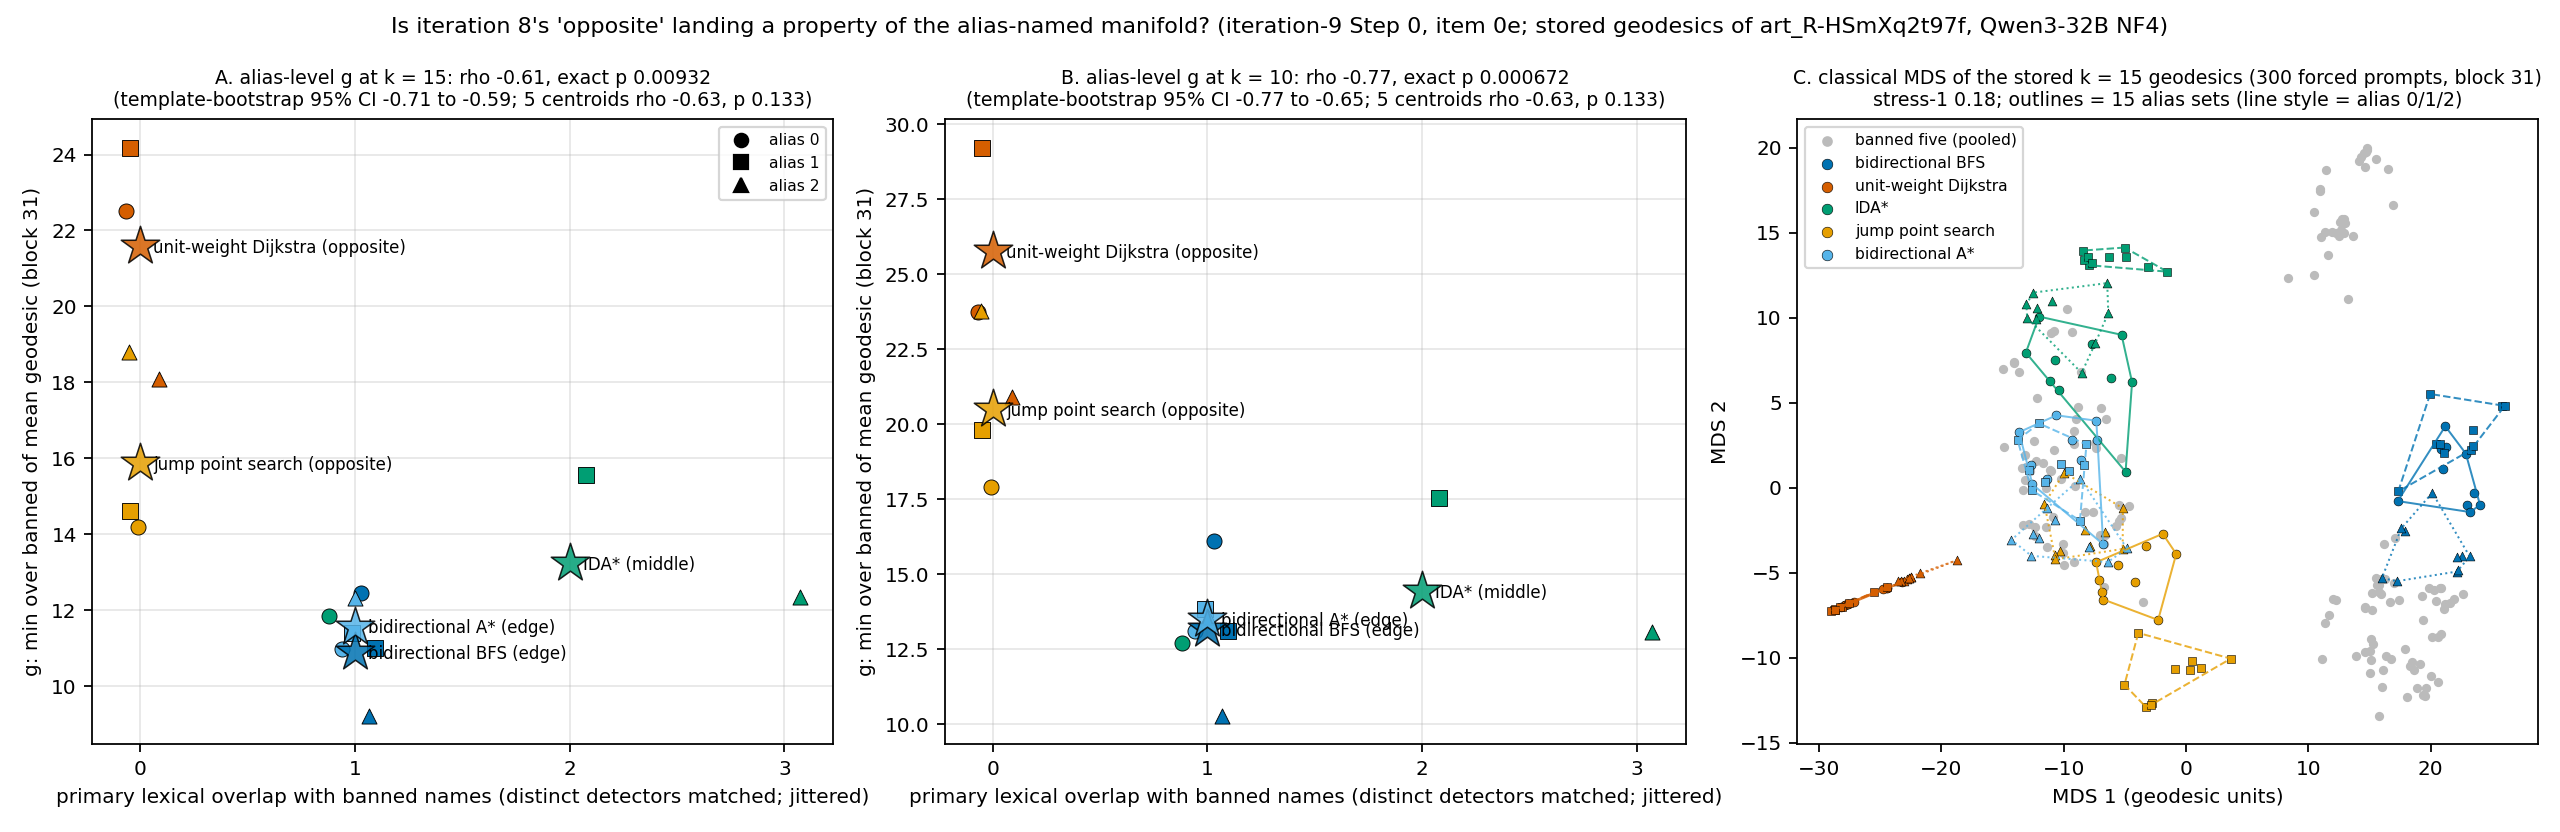

gates: {'E1_labels_equal': True, 'E2_multiset_equal_forced_set': True, 'E2_order_equal_forced_set': True, 'E2_template_field_consistent': True, 'E3_g_matches_M1': True, 'E4_pass': None, 'E4_spearman_vs_stored_k15': None, 'hard_gates_pass': True}
E3 max |g - stored M1 g|: {'k15': 0.0, 'k10': 0.0} | classes k15: {'bibfs': 'EDGE', 'dijkstra_unit': 'OPPOSITE', 'idastar': 'MIDDLE', 'jps': 'OPPOSITE', 'biastar': 'EDGE'}
flags: ['states file not available: E1-E3 run on the vendored index, E4 not run', 'E4_not_run: states file not available']
primary overlap multiset: {0: 6, 1: 7, 2: 1, 3: 1} | null sizes: {'primary_exact': 360360, 'binary_exact': 5005, 'secondary_distinct': 5405400, 'secondary_method': 'monte_carlo_200000'}

algorithm / alias                                                  primary  second.    g k15    g k10
bibfs / bidirectional BFS                                                1    0.500   12.445   16.111
bibfs / bidirectional breadth-first search                          

In [18]:
display(Image(filename=str(ROOT / "figures/alias_overlap.png")))

print("gates:", {k: v for k, v in z["gates"].items() if k != "E3_detail"})
print("E3 max |g - stored M1 g|:", {k: v["max_abs_diff"] for k, v in z["gates"]["E3_detail"].items()},
      "| classes k15:", z["gates"]["E3_detail"]["k15"]["classes"])
print("flags:", z["flags"])
print("primary overlap multiset:", z["primary_multiset"], "| null sizes:", z["null_sizes"])
print()
print(f"{'algorithm / alias':<66}{'primary':>8}{'second.':>9}{'g k15':>9}{'g k10':>9}")
for r in z["overlap_rows"]:
    key = f"{r['algorithm']}|{r['alias_index']}"
    print(f"{r['algorithm'] + ' / ' + r['alias']:<66}{r['primary']:>8}{r['secondary']:>9.3f}"
          f"{z['per_k']['k15']['g_alias'][key]:>9.3f}{z['per_k']['k10']['g_alias'][key]:>9.3f}")
print()
print("verdict:", z["verdict"]["code"], "-", z["verdict"]["sentence"])

## `src/tertiary_bpe.py`: the optional BPE-token sensitivity

The committed scores look at words. The model, however, sees **BPE tokens**. This optional tertiary score, committed as optional, takes the token-set Jaccard of each alias against the banned aliases. Each alias is tokenized as it sits in the prompt, with a leading space, by the tokenizer of the very checkpoint whose states built the manifold, `unsloth/Qwen3-32B-bnb-4bit`. The script then reruns the 15-alias correlation (Monte Carlo null: 1.4×10^10 arrangements) and the within-algorithm test. Under BPE tokens every algorithm's aliases differ, so the stratified test uses all five algorithms.

The original reads `tokenizer.json` **offline** from the Hugging Face cache and skips the sensitivity when the file is absent. A fresh Colab has no such cache, so the notebook first tries to download the file at the exact revision the record used. That is the README's restore step, `huggingface-cli download unsloth/Qwen3-32B-bnb-4bit tokenizer.json`, about 11 MB. If the download fails, `main()` skips the sensitivity as committed.

Other changes:
- the cache path comes from `huggingface_hub`, which also covers Colab, where `HF_HUB_CACHE`/`HF_HOME` are unset;
- the alias table comes from the loaded data;
- `results/s0e.json` is the file `stage_0e()` just wrote.

In [19]:
from huggingface_hub import constants as hf_constants, hf_hub_download

# Notebook addition: put tokenizer.json into the HF cache at the revision the record used (the README's restore step).
# On any failure the file stays absent and main() skips the sensitivity, exactly as the original does offline.
try:
    hf_hub_download("unsloth/Qwen3-32B-bnb-4bit", "tokenizer.json", revision="7f721e74a6a8cc9ee352f7e49303a2c1705f9083")
except Exception as exc:  # noqa: BLE001 - any failure only leaves this optional sensitivity unrun, as committed
    print(f"tokenizer.json not available ({type(exc).__name__}: {exc}); the BPE sensitivity will be skipped")

# original: TP_SRC = RC.ART[RC.TP] / "src" (where common.py's ALIAS_TABLE was read; here it comes from `data`)
CACHE = str(Path(hf_constants.HF_HUB_CACHE)   # original: Path(os.environ.get("HF_HUB_CACHE") or Path(os.environ.get("HF_HOME", "")) / "hub")
            / "models--unsloth--Qwen3-32B-bnb-4bit" / "snapshots" / "*" / "tokenizer.json")


@logger.catch(reraise=True)
def main() -> dict | None:
    paths = sorted(glob.glob(CACHE))
    if not paths:
        logger.warning("tokenizer not cached offline: tertiary score not run (as committed)")
        return None
    tok = Tokenizer.from_file(paths[0])
    alias_table = data["inputs"]["common_py"]["ALIAS_TABLE"]   # original: AG.read_literal(TP_SRC / "common.py", "ALIAS_TABLE")
    ids = lambda s: set(tok.encode(" " + s, add_special_tokens=False).ids)  # noqa: E731 - alias as it sits in the prompt
    banned = [ids(s) for b in AG.BANNED for s in alias_table[b]]
    rows = []
    for a in AG.NONBANNED:
        for j, s in enumerate(alias_table[a]):
            t = ids(s)
            jac = max(len(t & b) / len(t | b) for b in banned)
            rows.append({"algorithm": a, "alias_index": j, "alias": s, "bpe_tokens": tok.encode(" " + s, add_special_tokens=False).tokens,
                         "tertiary": jac})
    x3 = np.array([r["tertiary"] for r in rows])
    z = json.loads((ROOT / "results/s0e.json").read_text())
    rng = np.random.default_rng(AG.SEED + 3)
    n_dist = AG.n_distinct_assignments(list(x3))
    null = S0E.exact_null(x3) if n_dist <= 2_000_000 else S0E.mc_null(x3, AG.N_MC_SECONDARY, rng)
    out = {"tokenizer": paths[0].split("hub/")[1], "rows": rows, "n_distinct_arrangements": n_dist,
           "null": "exact" if n_dist <= 2_000_000 else f"monte_carlo_{AG.N_MC_SECONDARY}", "per_k": {}}
    for k in ("k15", "k10"):
        g = np.array([z["per_k"][k]["g_alias"][f"{a}|{j}"] for a in AG.NONBANNED for j in range(3)])
        r = AG.spearman(g, x3)
        st = AG.stratified_exact(g.reshape(5, 3), x3.reshape(5, 3))
        out["per_k"][k] = {"rho_tertiary": r, **S0E.pvals(r, null), "stratified": st}
        logger.info(f"tertiary {k}: rho {r:.3f} p {out['per_k'][k]['p_lower']:.4f}; stratified {st['stat']:.3f} "
                    f"p {st['p_lower']:.3f}")
    (ROOT / "results/s0e_tertiary.json").write_text(json.dumps(out, indent=1, default=float))
    with (ROOT / "tables/alias_tertiary.csv").open("w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["algorithm", "alias_index", "alias", "bpe_tokens", "tertiary_bpe_jaccard", "g_k15", "g_k10"])
        for r in rows:
            key = f"{r['algorithm']}|{r['alias_index']}"
            w.writerow([r["algorithm"], r["alias_index"], r["alias"], " ".join(r["bpe_tokens"]), round(r["tertiary"], 6),
                        round(z["per_k"]["k15"]["g_alias"][key], 6), round(z["per_k"]["k10"]["g_alias"][key], 6)])
    return out


# Notebook glue, as for `AG` and `S0E`: eval.py calls tertiary_bpe.main()
tertiary_bpe = sys.modules[__name__]

## `eval.py`'s `main()`, part 2: the BPE sensitivity, and the stages that need the iteration-8 artifacts

`main()` runs the tertiary score next, then the stages that build the record repair itself. Those stages read the six iteration-8 artifacts and the report, which are not part of the demo data, so the notebook does not run them. Their recorded results appear in the final summary.

| stage | what it does in the full run | recorded result |
|-|-|-|
| `stage_ledger` (`src/recompute.py`) | recomputes every number a correction quotes, for four items. **0a** is the circuit; its layer-0 node's exact-zero held-out effect turns out to be an edit that was never applied. **0b** is the DAS fork verdict, **0c** the scope of the entropy and temperature-law claims, and **0f** the Gemma comparators | 298 values: 147 MATCH, 151 NEW, 0 CORRECTED, 0 CARRIED |
| `stage_edits` (`src/edits_spec.py`, `src/s0_extra.py`, `src/apply_lint.py`) | builds the 0d positioning table (11 neighbours checked live), the 0g figure markers and the 0e text, then the 49 `old_text → new_text` edits, the apply test (each `old_text` occurs exactly once, no overlaps) and the whole-report L1–L10 residual-claim lint | apply test passes; lint 28 → 0 unallowed hits |
| `write_corrections` | writes `corrections.json` and `apply_test.json` | 7 of 7 review items ANSWERED |
| `audit/rederive.py`, `audit/headline_rederive.py` | independent standard-library re-derivations, the second from raw per-row files, with placebos | 400 checks, 0 mismatches; 4/4 placebos fail as required |

In [20]:
os.environ.setdefault("HF_HUB_OFFLINE", "1")
tz = tertiary_bpe.main()
# led = RC.Ledger()                                   # not run (src/recompute.py reads the six iteration-8 artifacts)
# rec = stage_ledger(led)                             # not run: 0a / 0b / 0c / 0f value ledger
# ed = stage_edits(led, rec, z, tz)                   # not run: 0d positioning, 0g markers, 49 edits, apply test, lint
# corr = write_corrections(led, ed, man)              # not run: corrections.json, apply_test.json
# audit/rederive.py and audit/headline_rederive.py    # not run: stdlib audits over the iteration-8 files

if tz:   # notebook addition: show the tertiary score per alias and the two BPE statistics
    for r in tz["rows"]:
        print(f"{r['algorithm'] + ' / ' + r['alias']:<66} BPE Jaccard {r['tertiary']:.3f}  tokens {r['bpe_tokens']}")
    for k, v in tz["per_k"].items():
        print(f"{k}: rho {v['rho_tertiary']:.3f} (MC p {v['p_lower']:.4f}); within-algorithm {v['stratified']['stat']:.2f} "
              f"(exact p {v['stratified']['p_lower']:.3f} over {v['stratified']['n_arrangements_nominal']} relabelings)")

11:28:08|INFO   |tertiary k15: rho -0.768 p 0.0007; stratified -0.500 p 0.057


11:28:11|INFO   |tertiary k10: rho -0.779 p 0.0005; stratified -0.400 p 0.112


bibfs / bidirectional BFS                                          BPE Jaccard 0.333  tokens ['Ġbid', 'irectional', 'ĠBFS']
bibfs / bidirectional breadth-first search                         BPE Jaccard 0.500  tokens ['Ġbid', 'irectional', 'Ġbreadth', '-first', 'Ġsearch']
bibfs / a breadth-first search run from both start and goal        BPE Jaccard 0.400  tokens ['Ġa', 'Ġbreadth', '-first', 'Ġsearch', 'Ġrun', 'Ġfrom', 'Ġboth', 'Ġstart', 'Ġand', 'Ġgoal']
dijkstra_unit / unit-weight Dijkstra                               BPE Jaccard 0.000  tokens ['Ġunit', '-weight', 'ĠD', 'ijkstra']
dijkstra_unit / Dijkstra's algorithm with unit edge weights        BPE Jaccard 0.091  tokens ['ĠD', 'ijkstra', "'s", 'Ġalgorithm', 'Ġwith', 'Ġunit', 'Ġedge', 'Ġweights']
dijkstra_unit / a priority-queue Dijkstra search                   BPE Jaccard 0.222  tokens ['Ġa', 'Ġpriority', '-', 'queue', 'ĠD', 'ijkstra', 'Ġsearch']
idastar / IDA* search                                              BPE Jaccard 0.400 

## `eval.py`: the output format (`CHECKLIST`, `ex()`)

`eval_out.json` follows the pipeline's `exp_eval_sol_out` schema: `{metadata, metrics_agg, datasets: [{dataset, examples}]}`.

- **`CHECKLIST`** lists the seven items of the blocking review (0a–0g) with their severity and evidence files.
- **`ex()`** turns one record into an example with an `input` and an `output`, plus fields sorted by prefix:
  - `predict_*` fields hold strings;
  - `eval_*` fields hold floats, and missing ones (NaN or None, such as an arm that was not run) are **omitted, never written as NaN**;
  - every other keyword becomes a `metadata_*` field.

The full run builds ten datasets: corrections, report_edits, circuit_heldout, occurrences_29of30, entropy_scope, positioning_rows, alias_overlap, gemma_arms, figure_markers and lint_hits.

In [21]:
CHECKLIST = {
    "0a": ("MUST-FIX", "Circuit shape and the unapplied held-out arm", "tables/circuit_heldout.csv; results/s0_core.json#0a"),
    "0b": ("MUST-FIX", "Qwen3-8B fork NO HANDLE under the committed rule", "art_e-_q5mSJGrSb:results/analysis.json#verdicts"),
    "0c": ("MUST-FIX", "Entropy superlative and temperature-law scope", "tables/entropy_scope.csv; tables/law_scope.csv"),
    "0d": ("MUST-FIX", "Iteration-8 positioning table", "tables/positioning_rows.csv; audit/web/"),
    "0e": ("MUST-FIX", "Alias-named manifold", "results/s0e.json; tables/alias_stats.csv; figures/alias_overlap.png"),
    "0f": ("minor", "Gemma comparators", "tables/gemma_arms.csv"),
    "0g": ("minor", "Missing figure markers", "figure_markers.json"),
}


def ex(inp: str, out: str, **kw: Any) -> dict[str, Any]:
    d = {"input": inp, "output": out}
    if not any(k.startswith("predict_") for k in kw):
        d["predict_s0"] = out
    for k, v in kw.items():
        if k.startswith("eval_"):
            if v is None or (isinstance(v, float) and v != v):
                continue                      # not available (e.g. an arm that was not run): omit, never NaN
            d[k] = float(v)
        elif k.startswith("predict_"):
            d[k] = str(v)
        else:
            d[f"metadata_{k}"] = v
    return d

## `eval.py`: `write_eval_out()`, the item-0e part

The cell below takes the lines of `write_eval_out(led, rec, z, ed, corr, audit)` that depend only on the 0e results `z` and the BPE results `tz`, in their original order:
- the `alias_*` entries of `metrics_agg`: 28 in the record, 27 here, because `alias_gate_E4_spearman` is omitted when E4 does not run;
- the `alias_overlap` dataset: 15 alias-set examples and 5 centroid examples;
- `metadata.sections["0e"]`.

The four `alias_bpe_*` metrics come from the value ledger in the original (`led.by["0e.k15.bpe_rho"]` and so on). The ledger stores exactly the `tz` values used here.

`eval.py` also writes `full_eval_out.json`, `mini_eval_out.json` and `preview_eval_out.json`, and finally asserts that the 53 hashed inputs are unchanged. Neither step applies to this partial output.

In [22]:
# From write_eval_out(led, rec, z, ed, corr, audit): the lines that need only z (and tz), in their original order
k15, k10 = z["per_k"]["k15"], z["per_k"]["k10"]
st = k15["stratified_secondary"]
c5 = k15["five_centroid_primary"]
metrics = {
    # original: "items_answered" ... "das_*", "entropy_*", "law_*", "positioning_*" (from corr / rec / ed; not run here)
    "alias_gate_E1": int(z["gates"]["E1_labels_equal"]), "alias_gate_E2": int(z["gates"]["E2_multiset_equal_forced_set"]),
    "alias_gate_E3": int(z["gates"]["E3_g_matches_M1"]),
    **({"alias_gate_E4_spearman": z["gates"]["E4_spearman_vs_stored_k15"]}
       if z["gates"].get("E4_spearman_vs_stored_k15") is not None else {}),
    "alias_rho_k15": k15["rho_primary"], "alias_p_k15": k15["primary_p_lower"],
    "alias_rho_k15_ci_low": k15["ci95_primary"][0], "alias_rho_k15_ci_high": k15["ci95_primary"][1],
    "alias_rho_k10": k10["rho_primary"], "alias_p_k10": k10["primary_p_lower"],
    "alias_rho_k15_secondary": k15["rho_secondary"], "alias_p_k15_secondary": k15["secondary_p_lower"],
    "alias_rho_5centroid": c5["rho"], "alias_p_5centroid": c5["p_lower"], "alias_5centroid_floor": c5["floor_lower"],
    "alias_stratified_stat": st["stat"], "alias_stratified_p": st["p_lower"], "alias_fe_beta": st["beta"],
    "alias_fe_beta_p_two_sided": st["beta_p_two_sided"],
    "alias_placebo_P1_reject_rate": z["placebos"]["P1_shuffled_alias_labels"]["share_p_lt_0.05"],
    "alias_placebo_P2_reject_rate": z["placebos"]["P2_random_overlap_vector"]["share_p_lt_0.05"],
    "alias_placebo_P3_mean": z["placebos"]["P3_within_algorithm_shuffles"]["stat_mean"],
    "alias_planted_control_pass": int(z["placebos"]["C1_planted"]["seed0_succeeds"]),
    # original: led.by["0e.k15.bpe_rho"]["recomputed"], ... if "0e.k15.bpe_rho" in led.by (the ledger holds these tz values)
    **({"alias_bpe_rho_k15": tz["per_k"]["k15"]["rho_tertiary"],
        "alias_bpe_stratified_k15": tz["per_k"]["k15"]["stratified"]["stat"],
        "alias_bpe_stratified_p_k15": tz["per_k"]["k15"]["stratified"]["p_lower"],
        "alias_bpe_stratified_p_k10": tz["per_k"]["k10"]["stratified"]["p_lower"]} if tz else {}),
    "alias_verdict_confounded": int(z["verdict"]["code"] == "CONFOUNDED"),
    # original: "gemma_*", "figure_*", "audit_*" (from rec / ed / audit; not run here)
}
metrics = {k: (float(v) if isinstance(v, float) else int(v)) for k, v in metrics.items()}
ds = []
# original: ds.append(...) for corrections, report_edits, circuit_heldout, occurrences_29of30, entropy_scope, positioning_rows
order = [(a, j) for a in AG.NONBANNED for j in range(3)]
rows = z["overlap_rows"]
ds.append({"dataset": "alias_overlap", "examples": [
    ex(f"{a} alias {j}: {r['alias']}", f"g_k15 {k15['g_alias'][f'{a}|{j}']:.3f}", detectors=r["detectors"],
       eval_primary_overlap=r["primary"], eval_secondary_overlap=r["secondary"],
       eval_g_k15=k15["g_alias"][f"{a}|{j}"], eval_g_k10=k10["g_alias"][f"{a}|{j}"]) for (a, j), r in zip(order, rows)]
    + [ex(f"{a} (algorithm centroid)", f"g_k15 {k15['g_algorithm'][a]:.3f}", eval_g_k15=k15["g_algorithm"][a],
          eval_g_k10=k10["g_algorithm"][a]) for a in AG.NONBANNED]})
# original: ds.append(...) for gemma_arms, figure_markers, lint_hits
sections = {"0e": {}}   # original: {"edits", "values", "verdict"} for each of 0a-0g, from corr and the ledger
sections["0e"]["metrics"] = {k: z[k] for k in ("gates", "verdict", "placebos", "null_sizes", "flags")} | {
    "per_k": {k: {kk: vv for kk, vv in v.items() if kk not in ("g_alias",)} for k, v in z["per_k"].items()}}
sections["0e"]["verdict"] = z["verdict"]["sentence"]
flags = []              # original: + "direction_number_not_reproduced" if any ledger value is CORRECTED
meta = {"evaluation_name": "Iteration-9 Step 0: repair of the iteration-8 research record",
        "plan_id": "gen_plan_evaluation_1_idx1", "utc": dt.datetime.now(dt.timezone.utc).isoformat(),
        "sections": sections, "flags": flags,     # original also: "report_sha256": corr["report_sha256"]
        "outputs": ["results/s0e.json", "results/s0e_tertiary.json", "tables/alias_*.csv",
                    "figures/alias_overlap.(pdf|png)"]}   # original: the record's full output list
out = {"metadata": meta, "metrics_agg": metrics, "datasets": ds}
json.dumps(out, allow_nan=False, default=str)        # raises if any NaN or infinity slipped in
(ROOT / "eval_out.json").write_text(json.dumps(out, indent=1, default=str))
# original: after = {k: sha(p) for k, p in input_files()}; assert not changed   (inputs were not hashed here)
logger.info(f"done in {time.time() - t0:.0f} s; 0e metrics {len(metrics)}, alias_overlap examples "
            f"{len(ds[0]['examples'])}; eval_out.json sha256 {sha(ROOT / 'eval_out.json')[:16]}")

11:28:11|INFO   |done in 17 s; 0e metrics 27, alias_overlap examples 20; eval_out.json sha256 e743a9456373f725


## Results: does the notebook reproduce the record?

**The 0e metrics.** The table below lists each metric recomputed in this notebook next to the value the full run recorded in `full_eval_out.json` (`data["reference_full_run"]`). Metrics marked `*` depend on random draws: the bootstrap CI, the Monte Carlo p of the secondary score, and the placebo rates. They match the record only at the original sizes (`N_BOOT = 2000`, `N_PLACEBO = 1000`, `N_MC_SECONDARY = 200_000`), because every draw comes from one seeded stream. Every other metric is exact and must match at any configuration.

**The dataset.** The 20 rebuilt `alias_overlap` examples are compared field by field with the examples stored in `mini_demo_data.json`.

**The rest of the repair.** The summary repeats the recorded results of the stages that need the iteration-8 artifacts.

In [23]:
ref = data["reference_full_run"]
RANDOM = {"alias_rho_k15_ci_low", "alias_rho_k15_ci_high", "alias_p_k15_secondary", "alias_placebo_P1_reject_rate",
          "alias_placebo_P2_reject_rate", "alias_placebo_P3_mean"}   # depend on the N_BOOT / N_MC_SECONDARY / N_PLACEBO draws


def _same(a, b) -> bool:
    if isinstance(a, float) or isinstance(b, float):
        return abs(a - b) <= 1e-9 * max(1.0, abs(b))
    return a == b


# 1. the 0e metrics against the record
print(f"{'metric  (* = from random draws)':<36}{'this notebook':>15}{'recorded':>15}   agree")
n_exact = n_exact_ok = n_rand_ok = 0
for k, v in metrics.items():
    r = ref["metrics_agg"].get(k)
    ok = r is not None and _same(v, r)
    if k in RANDOM:
        n_rand_ok += ok
    else:
        n_exact += 1
        n_exact_ok += ok
    print(f"{k + (' *' if k in RANDOM else ''):<36}{v:>15.6g}{(r if r is not None else float('nan')):>15.6g}   "
          f"{'yes' if ok else 'NO'}")
missing = [k for k in ref["metrics_agg"] if k.startswith("alias_") and k not in metrics]
print(f"\nexact metrics that agree with the record: {n_exact_ok} of {n_exact}; random-draw metrics that agree: "
      f"{n_rand_ok} of {len(RANDOM)} (N_BOOT={N_BOOT}, N_PLACEBO={N_PLACEBO}, N_MC_SECONDARY={N_MC_SECONDARY})")
print(f"recorded but not recomputed here: {missing} (E4 needs the 181 MB states file)")

# 2. the alias_overlap dataset, field by field
mine = {e["input"]: e for e in ds[0]["examples"]}
same = [e["input"] for e in data["examples"]
        if e["input"] in mine and mine[e["input"]].keys() == e.keys() and all(_same(mine[e["input"]][f], e[f]) for f in e)]
print(f"alias_overlap examples identical to full_eval_out.json: {len(same)} of {len(data['examples'])}")

# 3. the rest of the repair, as recorded by the full run
m = ref["metrics_agg"]
print("\nThe whole repair, as recorded by the full run (these stages need the six iteration-8 artifacts):")
for it, v in ref["item_checklist"].items():
    print(f"  {it} [{v['severity']:<8}] {v['item']:<50} {v['status']} ({v['n_edits']} edits)")
print(f"  {ref['n_edits']} edits; apply test {'passes' if ref['apply']['apply_test_pass'] else 'FAILS'}; residual-claim lint "
      f"{ref['apply']['lint_before']} -> {ref['apply']['lint_after']} unallowed hits")
print(f"  value ledger: {ref['n_values']} values {ref['values_by_status']}")
print(f"  0a circuit: L0 condition-MLP pair-prompt effects {m['circuit_L0_pair_mean_ablate']:.2f} (ablate) and "
      f"{m['circuit_L0_pair_mean_steer']:.2f} (steer) nats; held-out prompts sharing a pair template: "
      f"{m['circuit_cond_span_matches_heldout']} of 10, so its 0.00 held-out effect is an unapplied edit")
print(f"  0b DAS fork (Qwen3-8B, toward BFS): {m['das_T10_bfs_written']} of 30 programs write BFS but only "
      f"{m['das_T10_bfs_correct']} are correct, so the pass-rate part of the committed rule fails -> NO HANDLE "
      f"(McNemar against random edits: exact p {m['das_T10_bfs_mcnemar_p']})")
print(f"  0c fork entropy above the twin's 90th percentile in all {m['entropy_n_twin_samples_above_q90']} samples; "
      f"temperature law passes {m['law_units_pass']} of 6 units (sign test against the flat law p "
      f"{m['law_sign_test_p_vs_flat']:.2f})")
print(f"  0d positioning: {m['positioning_rows']} rows; {m['positioning_live_verified']} neighbours VERIFIED and "
      f"{m['positioning_live_verified_abstract']} VERIFIED-ABSTRACT live")
print(f"  0f Gemma: {m['gemma_families_twin_fallback']} comparator families scored at the twin-level fallback; "
      f"0g: {m['figure_markers_added']} figure markers added")
print(f"  audits: {m['audit_n_checks']} checks, {m['audit_n_mismatches']} mismatches, {m['audit_placebos_failed']}/4 "
      f"placebos fail as required; raw-row headlines all match: {bool(m['audit_raw_headlines_all_match'])}")

metric  (* = from random draws)       this notebook       recorded   agree
alias_gate_E1                                     1              1   yes
alias_gate_E2                                     1              1   yes
alias_gate_E3                                     1              1   yes
alias_rho_k15                             -0.606848      -0.606848   yes
alias_p_k15                              0.00932401     0.00932401   yes
alias_rho_k15_ci_low *                    -0.708315      -0.708315   yes
alias_rho_k15_ci_high *                   -0.587335      -0.587335   yes
alias_rho_k10                             -0.766853      -0.766853   yes
alias_p_k10                             0.000671551    0.000671551   yes
alias_rho_k15_secondary                   -0.765083      -0.765083   yes
alias_p_k15_secondary *                     0.00083        0.00083   yes
alias_rho_5centroid                       -0.632456      -0.632456   yes
alias_p_5centroid                          0.1333

## Visualization: why the verdict is CONFOUNDED

- **A. The committed test against its exact null.** The histogram shows all 360,360 arrangements of the primary overlap multiset. The observed rho at k = 15 and at k = 10 sits deep in the lower tail. The shaded band is the template-bootstrap interval at k = 15.
- **B. Across versus within algorithms**, on the content-word overlap. The stars (algorithm centroids) fall steeply with overlap. Inside each algorithm (a connected line through its three aliases), no consistent slope remains. Dijkstra and jump point search have zero overlap for all three aliases, so they form vertical lines and drop out of the within-algorithm test.
- **C. The geometry itself.** This is the stored k = 15 geodesic matrix between the 300 forced prompts, sorted by algorithm. Its block structure is the manifold on which the test runs.

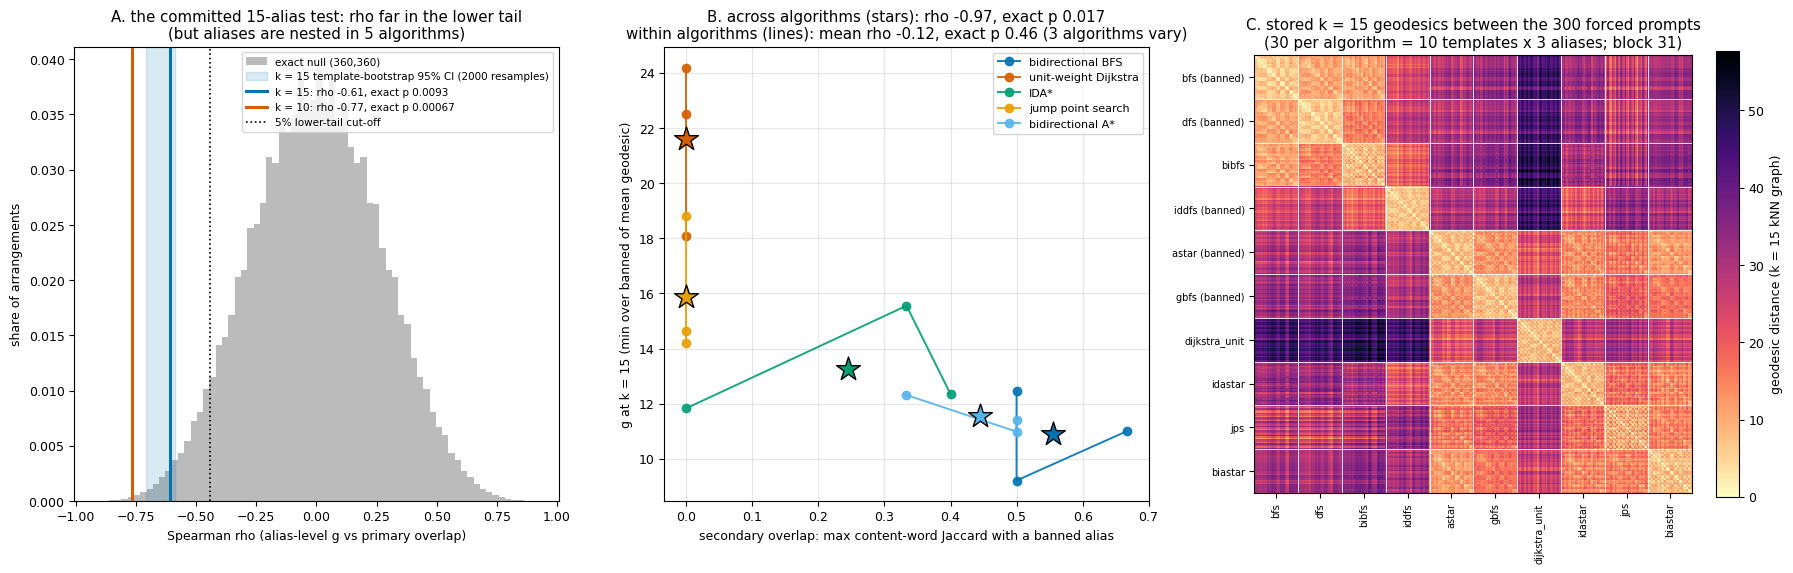

In [24]:
x1 = np.array([r["primary"] for r in z["overlap_rows"]], dtype=float)
null1 = S0E.exact_null(x1)   # the same 360,360-arrangement null that run() used for the committed test
geo15 = np.array(data["inputs"]["geo_C6_nf4"]["geo_k15"], dtype=np.float64)
labels_geo = np.array(data["inputs"]["geo_C6_nf4"]["labels"])
canon = data["inputs"]["common_py"]["CANON_ORDER"]
col = {"bibfs": "#0072B2", "biastar": "#56B4E9", "idastar": "#009E73", "jps": "#E69F00", "dijkstra_unit": "#D55E00"}

fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))

# A. the committed 15-alias test against its exact null
ax = axes[0]
ax.hist(null1, bins=70, color="#BBBBBB", weights=np.full(len(null1), 1 / len(null1)), label="exact null (360,360)")
lo, hi = z["per_k"]["k15"]["ci95_primary"]
ax.axvspan(lo, hi, color="#0072B2", alpha=0.15, label=f"k = 15 template-bootstrap 95% CI ({N_BOOT} resamples)")
for k, c in (("k15", "#0072B2"), ("k10", "#D55E00")):
    d = z["per_k"][k]
    ax.axvline(d["rho_primary"], color=c, lw=2.2,
               label=f"{k.replace('k', 'k = ')}: rho {d['rho_primary']:.2f}, exact p {d['primary_p_lower']:.2g}")
ax.axvline(np.quantile(null1, 0.05), color="k", ls=":", lw=1.2, label="5% lower-tail cut-off")
ax.set_xlabel("Spearman rho (alias-level g vs primary overlap)")
ax.set_ylabel("share of arrangements")
ax.set_title("A. the committed 15-alias test: rho far in the lower tail\n(but aliases are nested in 5 algorithms)")
ax.legend(fontsize=7.5, loc="upper right")

# B. across algorithms (stars) vs within algorithms (lines through each algorithm's three aliases)
ax = axes[1]
gk = z["per_k"]["k15"]["g_alias"]
for a in AG.NONBANNED:
    xs = np.array([r["secondary"] for r in z["overlap_rows"] if r["algorithm"] == a])
    ys = np.array([gk[f"{a}|{j}"] for j in range(3)])
    o = np.argsort(xs, kind="stable")
    ax.plot(xs[o], ys[o], "-o", color=col[a], lw=1.4, ms=6, alpha=0.9, label=AG.DISPLAY[a])
    ax.scatter(xs.mean(), z["per_k"]["k15"]["g_algorithm"][a], marker="*", s=320, color=col[a], edgecolor="k",
               zorder=4)
st, c5s = z["per_k"]["k15"]["stratified_secondary"], z["per_k"]["k15"]["five_centroid_secondary"]
ax.set_title(f"B. across algorithms (stars): rho {c5s['rho']:.2f}, exact p {c5s['p_lower']:.3f}\n"
             f"within algorithms (lines): mean rho {st['stat']:.2f}, exact p {st['p_lower']:.2f} "
             f"({st['n_algorithms_used']} algorithms vary)")
ax.set_xlabel("secondary overlap: max content-word Jaccard with a banned alias")
ax.set_ylabel("g at k = 15 (min over banned of mean geodesic)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)

# C. the stored geometry: the k = 15 geodesic matrix, sorted by algorithm
ax = axes[2]
im = ax.imshow(geo15, cmap="magma_r", interpolation="nearest")
blocks_ix = [np.where(labels_geo == a)[0] for a in canon]
for ix in blocks_ix[1:]:
    ax.axhline(ix[0] - 0.5, color="w", lw=0.6)
    ax.axvline(ix[0] - 0.5, color="w", lw=0.6)
ticks = [ix.mean() for ix in blocks_ix]
names = [f"{a} (banned)" if a in AG.BANNED else a for a in canon]
ax.set_xticks(ticks)
ax.set_xticklabels(canon, rotation=90, fontsize=7)
ax.set_yticks(ticks)
ax.set_yticklabels(names, fontsize=7)
plt.colorbar(im, ax=ax, fraction=0.046, label="geodesic distance (k = 15 kNN graph)")
ax.set_title("C. stored k = 15 geodesics between the 300 forced prompts\n(30 per algorithm = 10 templates x 3 aliases; block 31)")

fig.tight_layout()
plt.show()

## Takeaways

- **The manifold test reproduces from the stored state.** From iteration 8's stored geodesics alone, the notebook reproduces the gates (E1–E3), every exact statistic of item 0e, the verdict and the `alias_overlap` dataset. At the original sample sizes it also reproduces the bootstrap, Monte Carlo and placebo numbers.
- **"Opposite" follows names, but only through the algorithms.** Across algorithms, an alias set's distance to the banned five tracks how much its *name* overlaps with banned names (rho −0.61 at k = 15, −0.77 at k = 10). Within an algorithm the effect vanishes (−0.12, p 0.46). On the model's own BPE tokens the within-algorithm statistic is a borderline −0.50 (p 0.057), so a small name effect is not excluded. On this manifold, names and mechanisms are **confounded**.
- **What decides it next.** Iteration 8's "edge versus opposite" reading of the prohibition experiment cannot be attributed to mechanism from this alias-named manifold. The record now says so, and leaves the question to the name-free manifolds of the next step (TP-G).
- **The rest of the record.** The repair also answers the six other review items: 49 tagged edits, a 298-value ledger with no CORRECTED values, lint 28 → 0, and audits with 0 mismatches. `report_corrected.md` in the artifact is the record to use from now on.

**Running the full artifact.** Clone the run repository, place the six iteration-8 artifacts as sibling folders (or set `S0_DEPS_DIR`), and run `uv run eval.py --stages all`. That takes about 40 s on CPU and also runs both audits.